In [1]:
from tensorboard.backend.event_processing import event_accumulator
import pandas as pd
import numpy as np
import scipy
import math
import os
import re
import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import multiprocessing as mp
from collections import defaultdict

sns.set()

def parse_tensorboard(path, scalars):
    """returns a dictionary of pandas dataframes for each requested scalar"""
    ea = event_accumulator.EventAccumulator(
        path,
        size_guidance={event_accumulator.SCALARS: 0},
    )
    _absorb_print = ea.Reload()

    # make sure the scalars are in the event accumulator tags
    print_name = False
    for s in scalars:
        if s not in ea.Tags()["scalars"]:
            print_name = True
            print(s)
    if print_name:
        print(path)
    # assert all(
    #     s in ea.Tags()["scalars"] for s in scalars
    # ), "some scalars were not found in the event accumulator"
    new_scalars = [s for s in scalars if s in ea.Tags()["scalars"]]
    return {k: pd.DataFrame(ea.Scalars(k)) for k in new_scalars}

In [3]:
scalars = [
  'loss/train/total',
  'throughput/device/tokens_per_sec',
  'throughput/tokens_per_sec',
  'time/train',
  # 'metrics/babymmlu/5-shot/InContextLearningMultipleChoiceAccuracy',
  # 'metrics/rummlu/5-shot/InContextLearningMultipleChoiceAccuracy',
  # 'metrics/ruopenbookqa/0-shot/InContextLearningMultipleChoiceAccuracy',
  # 'metrics/boolq/0-shot/InContextLearningMultipleChoiceAccuracy',
  # 'metrics/hellaswag/0-shot/InContextLearningMultipleChoiceAccuracy',
  # 'metrics/ruworldtree/0-shot/InContextLearningMultipleChoiceAccuracy',
  # 'metrics/winogrande/0-shot/InContextLearningMultipleChoiceAccuracy',
]

LOG_DIR="/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real"
# LOG_DIR="/home/jovyan/ndermolaev/tensorboard/gigaseek_scaling_laws_4k/hyperopt_drop_0.6"

In [4]:
EMA_STEP=50
SMOOTHING=0.8

In [5]:
def process_path(full_path):
    # full_path = os.path.join(LOG_DIR, path)
    print(full_path)
    # print(os.path.realpath(full_path))
    # if full_path != os.path.realpath(full_path):
    #     return parse_tensorboard(os.path.realpath(full_path).replace("/tensorboard_papaya_o5/moe_scaling_laws_debug/vmamedov", ""), scalars)
    # else:
    return parse_tensorboard(full_path, scalars)

def read_tb(result, prefix, suffix, exp_list=None, dir=LOG_DIR):
    if exp_list is None:
        exp_list = os.listdir(dir)
    paths = [os.path.join(dir, path) for path in os.listdir(dir) if path.startswith(prefix) and path.endswith(suffix) and path not in result and path in exp_list]
    
    num_processes = min(mp.cpu_count(), min(len(paths), 128))
    
    print(num_processes, paths)

    # result = dict()

    with mp.Pool(num_processes) as pool:
        # Use imap to iterate over the paths in parallel
        for path, data in tqdm.tqdm(zip(paths, pool.imap(process_path, paths)), total=len(paths)):
            result[path] = data

    # for path in tqdm.tqdm(paths, total=len(paths)):
    #     result[path] = process_path(path)

    # return result

In [6]:
import pandas as pd
import numpy as np

from scipy.signal import lfilter

def smooth(scalars: list[float], weight: float) -> list[float]:  # Weight between 0 and 1
    last = scalars[0]  # First value in the plot (first timestep)
    smoothed = list()
    for point in scalars:
        smoothed_val = last * weight + (1 - weight) * point  # Calculate smoothed value
        smoothed.append(smoothed_val)                        # Save it
        last = smoothed_val                                  # Anchor the last smoothed value
        
    return smoothed

def smooth_f(df_, weight = 0.5):
    scalars = df_['value'].values
    df_['value'] = np.array(smooth(scalars.tolist(), weight))
    return df_

In [7]:
def gen_loss_matrix(tb_logs, strategy='mean'):
    result = tb_logs

    current_matrix = []
    for path in result:
        # bs_power = int(re.search(r"(\d+)bspow", path).group(1))
        # bs = 2 ** bs_power
        # lr = 2 ** (-float(re.search(r"-(\d+\.?\d?)lrpow", path).group(1)))
        # lr = round(lr, 5)

        _, _, lr, bs, _ = path.split("_")
        lr = float(lr[2:])
        bs = int(bs[2:-1])
        if strategy == 'mean':
            result[path]['loss/train/total_smooth'] = smooth_f(result[path]['loss/train/total'], SMOOTHING)
        
            #mean strategy
            # mean_step = 2 ** (22 - bs_power) * 10 # 10 step 4M, 20 step 2M, 40 step 1M and etc.
            mean_step = 40000 // bs
            loss_mean = result[path]['loss/train/total_smooth']['value'].values[-mean_step:].mean()
        elif strategy == 'min':
            result[path]['loss/train/total_smooth_99'] = smooth_f(result[path]['loss/train/total'], 0.99)
            #min strategy
            loss_mean = result[path]['loss/train/total_smooth_99']['value'].min()
        elif strategy == 'baby':
            loss_mean = -result[path]['metrics/babymmlu/5-shot/InContextLearningMultipleChoiceAccuracy']['value'].values.max()
        else:
            raise ValueError("strategy must be either mean or min")
    
        #loss_mean = result[path]['loss/train/total']['value'].ewm(span=ewa_step, adjust=False).mean().values[-ewa_step:].mean()
        current_matrix.append([bs, lr, loss_mean])

    loss_matrix = pd.DataFrame(current_matrix, columns=["bs", "lr", "loss_mean"]).pivot(index='bs', columns='lr', values='loss_mean')
    return loss_matrix

In [8]:
import pandas as pd
import numpy as np

from scipy.signal import lfilter

def smooth(scalars: list[float], weight: float) -> list[float]:  # Weight between 0 and 1
    last = scalars[0]  # First value in the plot (first timestep)
    smoothed = list()
    for point in scalars:
        smoothed_val = last * weight + (1 - weight) * point  # Calculate smoothed value
        smoothed.append(smoothed_val)                        # Save it
        last = smoothed_val                                  # Anchor the last smoothed value
        
    return smoothed

def smooth_f(df_, weight = 0.5):
    scalars = df_['value'].values
    df_['value'] = np.array(smooth(scalars.tolist(), weight))
    return df_

In [9]:
def gen_loss_matrix_rel(loss_matrix):
    loss_matrix_rel = loss_matrix.copy()
    minimum = loss_matrix_rel.values.min()
    loss_matrix_rel = (loss_matrix_rel - minimum).abs()
    loss_matrix_rel /= abs(minimum)
    loss_matrix_rel *= 100.0
    
    return loss_matrix_rel

In [10]:
def plot_heat_map(result, exp_name, relative=False, tag='loss_matrix_smooth_mean', result_old = None):
    if relative:
        #plot_matrix = result[exp_name]['loss_matrix_rel']
        plot_matrix = gen_loss_matrix_rel(result[exp_name][tag])
        if result_old is not None:
            plot_matrix_old = gen_loss_matrix_rel(result_old[exp_name][tag])
    else:
        plot_matrix = result[exp_name][tag]
        if result_old is not None:
            plot_matrix_old = result_old[exp_name][tag]

    fig, axes = plt.subplots(1, 4 if result_old is not None else 2, figsize=(28, 5))

    sns.heatmap(plot_matrix, 
                cmap="YlGnBu", 
                annot=True, 
                fmt=".3f", ax=axes[0])
    axes[0].set_title(f"{exp_name} | {tag}")

    sns.heatmap(result[exp_name]["finished_pct_table"], 
                cmap="YlGnBu", 
                annot=True, 
                fmt=".3f", ax=axes[1])
    axes[1].set_title(f"{exp_name} | 'finished_pct_table'")

    if result_old is not None:
        sns.heatmap(plot_matrix_old, 
                    cmap="YlGnBu", 
                    annot=True, 
                    fmt=".3f", ax=axes[2])
        axes[2].set_title(f"{exp_name} | {tag} old")


        sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)), 
                    cmap="YlGnBu", 
                    annot=True, 
                    fmt=".2f", ax=axes[3])
        axes[3].set_title(f"{exp_name} | perf table")

    plt.show()

    # sns.heatmap(result[exp_name]["finished_pct_table"], 
    #             cmap="YlGnBu", 
    #             annot=True, 
    #             fmt=".3f")
    # plt.title(f"{exp_name} | finished_pct")
    # plt.show()

In [11]:
def log_2(x):
    return np.log(x) / np.log(2)

In [12]:
result = dict()

In [13]:

read_tb(result, "", "")
for exp in result:
    for key in result[exp]:
        result[exp][key] = result[exp][key].dropna()

128 ['/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds1.83B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds10.98B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds21.96B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds4.575B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds7.32B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds1.83B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds10.98B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds21.96B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds4.575B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_

  0%|          | 0/1031 [00:00<?, ?it/s]

/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds4.575B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds1.83B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds7.32B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds21.96B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds10.98B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs1048k_ds21.96B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds7.32B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs131k_ds4.575B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs262k_ds10.98B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/183M_moe_lr0.00195_bs262k_ds1.83B/

  0%|          | 1/1031 [00:47<13:35:56, 47.53s/it]

/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs262k_ds13.2B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs262k_ds19.8B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs262k_ds3.3B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs262k_ds39.6B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs262k_ds8.25B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs524k_ds13.2B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs524k_ds19.8B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs524k_ds3.3B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs524k_ds39.6B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/330M_moe_lr0.00781_bs524k_ds8.25B
/h

...

  3%|▎         | 28/1031 [23:22<9:30:03, 34.10s/it] 

/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00391_bs8388k_ds42.87B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00049_bs1048k_ds42.87B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00049_bs1048k_ds107.175B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs1048k_ds107.175B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs1048k_ds171.48B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs1048k_ds257.22B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs1048k_ds42.87B


  3%|▎         | 28/1031 [23:40<9:30:03, 34.10s/it]

/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs16777k_ds107.175B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs16777k_ds171.48B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs16777k_ds257.22B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs16777k_ds42.87B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs2097k_ds107.175B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs2097k_ds171.48B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs2097k_ds257.22B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs2097k_ds42.87B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_real/4287M_moe_lr0.00024_bs4194k_ds107.175B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_law

100%|██████████| 1031/1031 [45:45<00:00,  2.66s/it] 


In [27]:
cnt = 0
for exp in result:
    if "loss/train/total" in result[exp]:
        cnt += 1

In [28]:
print(cnt)

758


In [12]:
result_perf = dict()

In [13]:

read_tb(result_perf, "", "", dir="/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf")
for exp in result_perf:
    for key in result_perf[exp]:
        result_perf[exp][key] = result_perf[exp][key].dropna()

42 ['/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs1048k_ds11.68B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs16777k_ds11.68B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs2097k_ds11.68B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs4194k_ds11.68B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs524k_ds11.68B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs8388k_ds11.68B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs1048k_ds1.83B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs131k_ds1.83B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs2097k_ds1.83B', '/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_

  0%|          | 0/42 [00:00<?, ?it/s]

/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs1048k_ds11.68B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs16777k_ds11.68B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs2097k_ds11.68B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs8388k_ds11.68B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs4194k_ds11.68B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs524k_ds11.68B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs1048k_ds1.83B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs131k_ds1.83B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs262k_ds1.83B/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs20

100%|██████████| 42/42 [00:10<00:00,  4.04it/s]


In [14]:
for key in list(result_perf.keys()):
    if "time/train" not in result_perf[key] or key.endswith("_re1") or key.endswith("_re2"):
        print(key)
        del result_perf[key]
    else:
        # print(result_perf[key]["throughput/tokens_per_sec"].shape)
        pass

/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs16777k_ds11.68B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/183M_moe_lr0.00195_bs2097k_ds1.83B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/2922M_moe_lr0.00049_bs33554k_ds29.22B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/330M_moe_lr0.00195_bs4194k_ds3.3B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/661M_moe_lr0.00391_bs8388k_ds6.61B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/4287M_moe_lr0.00024_bs67108k_ds42.87B
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs2097k_ds11.68B_re1
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs2097k_ds11.68B_re2
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf/1168M_moe_lr0.00098_bs4194k_ds11.68B_re1
/home/jovyan/vmamedov/tensorboard_papaya_o1/moe_scaling_laws_perf

In [15]:
perf_accum = defaultdict(dict)

for key in list(result_perf.keys()):
    run = key.split("/")[-1]
    ms, _, _, bs, _ = run.split("_")
    ms, bs = int(ms[:-1]), int(bs[2:-1])
    perf_accum[ms][bs] = bs / (result_perf[key]["time/train"]["value"].max() * 1000)
    # perf_accum[ms][bs] = 1

In [16]:
perf_accum_rel = perf_accum.copy()
for ms in perf_accum_rel:
    mn = float("inf")
    for bs in perf_accum_rel[ms]:
        mn = min(mn, perf_accum_rel[ms][bs])
    for bs in perf_accum_rel[ms]:
        perf_accum_rel[ms][bs] /= mn
        # perf_accum_rel[ms][bs] = 1.0



In [31]:
results_gathered = {}
for exp in result:
    if "loss/train/total" in result[exp]:
        size, _, lr, bs, tokens = exp.split("/")[-1].split("_")
        prefix = f"{size}_{tokens}"
        for name in result[exp]:
            result[exp][name] = result[exp][name].dropna()
        thr = result[exp]["loss/train/total"]["step"].max() / (float(tokens[2:-1]) * 10**9 / (float(bs[2:-1]) * 10**3))
        # if thr >= 0.95:
            # print(prefix, size, _, lr, bs, tokens)
        if prefix not in results_gathered:
            results_gathered[prefix] = defaultdict(dict)
        results_gathered[prefix]['tb_logs'][exp.split("/")[-1]] = result[exp]
        results_gathered[prefix]['finished_pct'][exp.split("/")[-1]] = thr

In [32]:
for prefix in results_gathered:
    results_gathered[prefix]['loss_matrix_smooth_mean'] = gen_loss_matrix(results_gathered[prefix]['tb_logs'], strategy='mean')
    results_gathered[prefix]['loss_matrix_smooth_min'] = gen_loss_matrix(results_gathered[prefix]['tb_logs'], strategy='min')
    results_gathered[prefix]['loss_matrix_rel'] = gen_loss_matrix_rel(results_gathered[prefix]['loss_matrix_smooth_mean'])

In [33]:
cnt_all = 0
cnt_not_found = 0

for prefix in results_gathered:
    size, tokens = prefix.split("_")
    results_gathered[prefix]["finished_pct_table"] = results_gathered[prefix]['loss_matrix_smooth_mean'].copy()
    for bs in results_gathered[prefix]["finished_pct_table"].index:
        for lr in results_gathered[prefix]["finished_pct_table"].columns:
            cnt_all += 1
            if f"{size}_moe_lr{lr}_bs{bs}k_{tokens}" in results_gathered[prefix]['finished_pct']:
                results_gathered[prefix]["finished_pct_table"].loc[bs, lr] = results_gathered[prefix]['finished_pct'][f"{size}_moe_lr{lr}_bs{bs}k_{tokens}"]
            else:
                cnt_not_found += 1
                print(f"{size}_moe_lr{lr}_bs{bs}k_{tokens} not found")
                results_gathered[prefix]["finished_pct_table"].loc[bs, lr] = np.nan


183M_moe_lr0.03125_bs131k_ds1.83B not found
183M_moe_lr0.0625_bs131k_ds1.83B not found
183M_moe_lr0.03125_bs262k_ds1.83B not found
183M_moe_lr0.0625_bs262k_ds1.83B not found
183M_moe_lr0.03125_bs524k_ds1.83B not found
183M_moe_lr0.0625_bs524k_ds1.83B not found
183M_moe_lr0.03125_bs131k_ds10.98B not found
183M_moe_lr0.0625_bs131k_ds10.98B not found
183M_moe_lr0.03125_bs262k_ds10.98B not found
183M_moe_lr0.0625_bs262k_ds10.98B not found
183M_moe_lr0.03125_bs524k_ds10.98B not found
183M_moe_lr0.0625_bs524k_ds10.98B not found
183M_moe_lr0.03125_bs131k_ds21.96B not found
183M_moe_lr0.0625_bs131k_ds21.96B not found
183M_moe_lr0.03125_bs262k_ds21.96B not found
183M_moe_lr0.0625_bs262k_ds21.96B not found
183M_moe_lr0.03125_bs524k_ds21.96B not found
183M_moe_lr0.0625_bs524k_ds21.96B not found
183M_moe_lr0.00195_bs2097k_ds21.96B not found
183M_moe_lr0.00391_bs2097k_ds21.96B not found
183M_moe_lr0.0625_bs2097k_ds21.96B not found
183M_moe_lr0.03125_bs131k_ds4.575B not found
183M_moe_lr0.0625_bs131

In [34]:
print(cnt_all, cnt_not_found)

900 142


In [2021]:
# with open("parsed_logs_with_tb.pck", "wb") as f:
#     pickle.dump(results_gathered_old, f)


with open("parsed_logs_with_tb_real.pck", "wb") as f:
    pickle.dump(results_gathered, f)

In [17]:
# with open("parsed_logs_with_tb.pck", "rb") as f:
#     results_gathered_old = pickle.load(f)

with open("parsed_logs_with_tb_real.pck", "rb") as f:
    results_gathered = pickle.load(f)


In [18]:

def find_opt_hp(results_gathered, prefix):
    mn = float("inf")
    bs_res, lr_res = None, None
    for lr in results_gathered[prefix]["loss_matrix_smooth_mean"].columns:
        for bs in results_gathered[prefix]["loss_matrix_smooth_mean"].index:
            if results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr] < mn:
                mn = results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr]
                bs_res, lr_res = bs, lr
    
    return bs_res, lr_res

def find_opt_lr(results_gathered, prefix):
    result = []
    for bs in results_gathered[prefix]["loss_matrix_smooth_mean"].index:
        mn = float("inf")
        lr_res = None
        for lr in results_gathered[prefix]["loss_matrix_smooth_mean"].columns:
            if results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr] < mn:
                mn = results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr]
                lr_res = lr
        
        result.append((bs, lr_res))
    
    return result


def find_similar_points(results_gathered, prefix, bs_res, lr_res, thr=0.0025):
    mn = results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs_res, lr_res]
    bs_list, lr_list = [], []
    for lr in results_gathered[prefix]["loss_matrix_smooth_mean"].columns:
        for bs in results_gathered[prefix]["loss_matrix_smooth_mean"].index:
            if abs(results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr] - mn) / max(mn, results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr]) <= thr:
                mn = results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr]
                bs_list.append(bs)
                lr_list.append(lr)

    return bs_list, lr_list


In [19]:

use_total_token_per_param = True
use_total_model_size = False

base_log_params = 10

sizes, tokens = set(), set()
data_mults = [10, 25, 40, 60, 120]

token_to_mult_bs = {
    
}

token_to_mult_lr = {
    
}

def fn_tokens_params_bs(tokens, params):
    return (tokens / params) ** 2

def fn_tokens_params_lr(tokens, params):
    return (tokens / params) ** 1

n_total_params = {
    "183M": 292,
    "330M": 369,
    "661M": 840,
    "1168M": 1395,
    "2922M": 3113,
    "4287M": 4679,
}

n_active_params = {
    "183M": 135,
    "330M": 178,
    "661M": 282,
    "1168M": 405,
    "2922M": 671,
    "4287M": 1007,
}

for key in results_gathered.keys():
    size, token = key.split("_")
    sizes.add(size)
    tokens.add(token)
    # token_to_mult[token] = int(float(token[2:-1]) * 10 ** 3 / float(size[:-1]))
    # assert token_to_mult[token] in data_mults
    token_to_mult_bs[token] = fn_tokens_params_bs(float(token[2:-1]) * 10 ** 9, (n_total_params[size] if use_total_token_per_param else n_active_params[size]) * 10 ** 6)
    token_to_mult_lr[token] = fn_tokens_params_lr(float(token[2:-1]) * 10 ** 9, (n_total_params[size] if use_total_token_per_param else n_active_params[size]) * 10 ** 6)

compute_per_token = {
    "183M": 523173888,
    "330M": 682573824,
    "661M": 1185607680,
    "1168M": 1784217600,
    "2922M": 3312549888,
    "4287M": 4680941568
}


In [20]:
from scipy.optimize import curve_fit
def func(x, a, b, c):
    return a * x ** (-b) + c

In [21]:
import copy

# ms_bs_ds_to_min_perf = {}
non_mon = 0
triplet_to_array = defaultdict(list)

for prefix in results_gathered:
    size, token = prefix.split("_")
    for lr in results_gathered[prefix]["loss_matrix_smooth_mean"].columns:
        for bs in results_gathered[prefix]["loss_matrix_smooth_mean"].index:
            triplet_to_array[(bs, lr, float(size[:-1]))].append((float(token[2:-1]) * 10 ** 9, results_gathered[prefix]["loss_matrix_smooth_mean"].loc[bs, lr]))

for prefix in results_gathered:
    if "perf_table" in results_gathered[prefix]:
        del results_gathered[prefix]["perf_table"]
    for key in results_gathered[prefix]["tb_logs"]:
        ms, _, lr, bs, ds = key.split("_")
        ms, lr, bs, ds = int(ms[:-1]), float(lr[2:]), int(bs[2:-1]), float(ds[2:-1])
        cur_val = results_gathered[prefix]["tb_logs"][key]["throughput/device/tokens_per_sec"].value.mean()
        # ms_bs_ds_to_min_perf[(ms, lr, ds)] = min(ms_bs_ds_to_min_perf.get((ms, lr, ds), float("inf")), cur_val)
        # ms_bs_ds_to_min_perf[(ms, lr, ds)] = min(ms_bs_ds_to_min_perf.get((ms, lr, ds), float("inf")), cur_val)
        if "perf_table" not in results_gathered[prefix]:
            results_gathered[prefix]["perf_table"] = results_gathered[prefix]["loss_matrix_smooth_mean"].copy()
        
        results_gathered[prefix]["perf_table"].loc[bs, lr] = perf_accum[ms].get(bs, np.nan)

results_gathered_copy = copy.deepcopy(results_gathered)

for bs, lr, ms in triplet_to_array:
    arr = sorted(triplet_to_array[(bs, lr, ms)])
    ms = int(ms)

    filtered_lst = []

    perf_lst = []

    for tokens, loss in arr:
        tokens /= 10**9
        # tokens = int(tokens)

        key = f"{ms}M_ds{tokens}B"

        info = results_gathered_copy[key]

        finished_pct = info["finished_pct_table"].loc[bs, lr]

        if finished_pct >= 0.95:
            filtered_lst.append((tokens, loss))
            perf_lst.append(info["tb_logs"][f"{ms}M_moe_lr{lr}_bs{bs}k_ds{tokens}B"]["throughput/device/tokens_per_sec"]["value"].mean())


    cond = sorted([x[1] for x in filtered_lst], reverse=True) == [x[1] for x in filtered_lst]

    if not cond:
        non_mon += 1

    if len(filtered_lst) >= 3 and cond:
        assert filtered_lst == sorted(filtered_lst)

        # filtered_lst.sort()
        # p1, p2, p3 = filtered_lst[0], filtered_lst[1], filtered_lst[-1]
        # p4 = 

        # a_0, b_0, c_0 = solve_abc_from_3(p1, p2, p3)
        # b_0 = -b_0

        a_0, b_0, c_0 = 1, 1, 0

        popt, _ = curve_fit(func, [x[0] for x in filtered_lst], [x[1] for x in filtered_lst], p0=[a_0, b_0, c_0], bounds=([0, 0, 0], [1000, 15, min([x[1] for x in filtered_lst])]), maxfev=100000)
        # , bounds=([0, 0, 0], [a_0 * 2 + 0.5, b_0 * 2 + 0.5, c_0 * 2 + 0.5])
        a,b,c = popt[0], popt[1], popt[2]
        # print(f"Old a, b, c: {a_0, b_0, c_0}, new a, b, c: {a,b,c}")
        # print(f"Rel diff: {(abs(a - a_0) + abs(b - b_0) + abs(c - c_0)) / max(abs(a) + abs(b) + abs(c), abs(a_0) + abs(b_0) + abs(c_0))}")

        for i, (tokens, _) in enumerate(filtered_lst):
            # real_ds = perf_lst[i] / ms_bs_ds_to_min_perf[(ms, lr, tokens)] * tokens
            real_ds = perf_accum_rel[ms].get(bs, 1.0) * tokens
            real_loss = a * (real_ds) ** (-b) + c
            # if ms == 183 and bs == 131 and tokens == 7.32:
            # print(f"Perf is equal to the min but loss is recalculated:")
                # print(f"Ds before: {tokens}, ds after: {real_ds}, loss before: {_}, loss after: {real_loss}")
                # print(f"Min perf: {ms_bs_ds_to_min_perf[(ms, lr, tokens)]}, current perf: {perf_lst[i]}")
                # print(f"Init list: {filtered_lst}")
                # print(f"Perf list: {perf_lst}")
                # print(f"Support points: p1 = {p1}, p2 = {p2}, p3 = {p3}")
                # print(f"Fitted law: a = {a}, b = {b}, c = {c}")
            if real_loss < 0:
                print(f"negative loss = {real_loss} encountered for model of size {ms}M and data size {tokens}B")
                # print(f"Min perf: {ms_bs_ds_to_min_perf[(ms, lr, tokens)]}, current perf: {perf_lst[i]}, real_ds: {real_ds}")
                print(f"Init list: {filtered_lst}")
                print(f"Perf list: {perf_lst}")
                print(f"Support points: p1 = {p1}, p2 = {p2}, p3 = {p3}")
                print(f"Fitted law: a = {a}, b = {b}, c = {c}")
                raise RuntimeError()

            key = f"{ms}M_ds{tokens}B"
            results_gathered_copy[key]["loss_matrix_smooth_mean"].loc[bs, lr] = real_loss

        # # Подготовим диапазон x для плавной кривой
        # xs_raw = np.array([x[0] for x in filtered_lst], dtype=float)
        # x_min, x_max = xs_raw.min(), xs_raw.max()
        # span = x_max - x_min
        # if span <= 0:
        #     span = max(1.0, x_max*0.5)
        # x_lo = max(0.5, x_min - 0.1*span)  # x>0 важно для x**b при небуквенных b
        # x_hi = x_max + 0.1*span
        # xs = np.linspace(x_lo, x_hi, 400)
        # ys = func(xs, a, b, c)

        # # Рисуем кривую и точки
        # plt.figure(figsize=(7, 4.5))
        # plt.plot(xs, ys, label=f"y = {a:.3g}·x^-{b:.3g} + {c:.3g}")
        # X = [x[0] for x in filtered_lst]
        # Y = [x[1] for x in filtered_lst]
        # plt.scatter(X, Y, s=60, label="Исходные точки")

        # # Подписываем точки
        # for i, (xx, yy) in enumerate(filtered_lst, start=1):
        #     plt.annotate(f"P{i}({xx:g},{yy:g})", (xx, yy), xytext=(5, 5),
        #                     textcoords="offset points")

        # plt.xlabel("x")
        # plt.ylabel("y")
        # plt.title("Аппроксимация y = a·x^b + c по 3 точкам и проверка 4-й")
        # plt.grid(True, alpha=0.3)
        # plt.legend()
        # plt.tight_layout()
        # plt.show()

        # # Дополнительно можно посмотреть ошибку на всех 4
        # for i, (xx, yy) in enumerate(filtered_lst, start=1):
        #     yhat = func(xx, a, b, c)
        #     print(f"P{i}: x={xx:g}, y_true={yy:g}, y_pred={yhat:.6g}, abs_err={yhat-yy:.6g}")



    else:
        for tokens, loss in arr:
            key = f"{ms}M_ds{tokens / 10**9}B"
            results_gathered_copy[key]["loss_matrix_smooth_mean"].loc[bs, lr] = np.nan



# a,b,c = solve_abc_from_3(p1, p2, p3)


/tmp/ipykernel_1587483/1259000551.py:69: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(func, [x[0] for x in filtered_lst], [x[1] for x in filtered_lst], p0=[a_0, b_0, c_0], bounds=([0, 0, 0], [1000, 15, min([x[1] for x in filtered_lst])]), maxfev=100000)


In [22]:

computes = []
# computes_correct = []
bathces = []
lrs = []
tokens = []
models = []
data_mults_bs = []
data_mults_lr = []
total_to_active_ratio = []

bs_lr_compute_triplets = []



# for prefix in results_gathered_copy:
for prefix in results_gathered_copy:
    # plot_heat_map(results_gathered, prefix, relative=False)
    size, token = prefix.split("_")
    mult_bs = token_to_mult_bs[token]
    mult_lr = token_to_mult_lr[token]
    bs_res, lr_res = find_opt_hp(results_gathered_copy, prefix)
    # print(prefix)
    # print(bs_res, lr_res)
    if bs_res is None or lr_res is None:
        continue

    bs_list, lr_list = find_similar_points(results_gathered_copy, prefix, bs_res, lr_res, 0.003)

    for bs, lr in zip(bs_list, lr_list):
        computes.append(math.log(compute_per_token[size] * float(token[2:-1]) * 10 ** 9))
        bathces.append(bs * 1000)
        lrs.append(lr)
        tokens.append(math.log(float(token[2:-1]) * 10 ** 9, 10))
        # models.append(math.log(float(size[:-1]) * 10 ** 6, 2))
        models.append(math.log(((n_total_params[size] * 10 ** 6) if use_total_model_size else (n_active_params[size] * 10 ** 6)), base_log_params))
        data_mults_bs.append(mult_bs)
        data_mults_lr.append(mult_lr)
        total_to_active_ratio.append(n_total_params[size] / n_active_params[size])


    bs_lr_pairs = find_opt_lr(results_gathered_copy, prefix)
    for bs, lr in bs_lr_pairs:
        bs_lr_compute_triplets.append((bs * 1000, lr, math.log(compute_per_token[size] * float(token[2:-1]) * 10 ** 9, 10)))


In [23]:
new_comp = []
new_bs = []
new_lr = []
new_tokens = []
new_models = []
new_data_mults_bs = []
new_data_mults_lr = []
new_param_ratios = []


for comp, bs, lr, token, model, mult_bs, mult_lr, ratio in zip([math.log(math.exp(x), 10) for x in computes], [math.log(x, 2) for x in bathces], [math.log(x, 2) for x in lrs], tokens, models, data_mults_bs, data_mults_lr, total_to_active_ratio):
    # if (round(lr + 5) == 0) or (round(lr + 9) == 0 and comp < 20) or (round(lr + 12) == 0):
    # if (round(lr + 12) == 0) or (round(bs - 20) == 0 and comp <= 18) or (round(bs - 21) == 0 and comp <= 18.5) or (round(bs - 22) == 0 and comp <= 19):
        # (round(lr + 9) == 0 and comp <= 19.5) or 
    bs_cond = (round(bs - 20) == 0 and comp <= 18) or (round(bs - 21) == 0 and comp <= 18.5) or (round(bs - 22) == 0 and comp <= 19)
    # if (round(lr + 6) == 0 and comp >= 18.5) or (round(lr + 7) == 0 and (comp <= 18.5 or comp >= 19.5)) or (round(lr + 8) == 0 and comp <= 19.2) or (round(lr + 9) == 0 and comp <= 19.5) or (round(lr + 12) == 0) or bs_cond:
        
    if (round(lr + 12) == 0) or (round(lr + 11) == 0):
    # if False:
        continue
    else:
        # if mult > 100:
        #     print(mult, bs, lr, 2 ** model, 10 ** token)
        new_comp.append(comp)
        new_bs.append(bs)
        new_lr.append(lr)
        new_tokens.append(token)
        new_models.append(model)
        new_data_mults_bs.append(mult_bs)
        new_data_mults_lr.append(mult_lr)
        new_param_ratios.append(ratio)

/tmp/ipykernel_1587483/3770608078.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


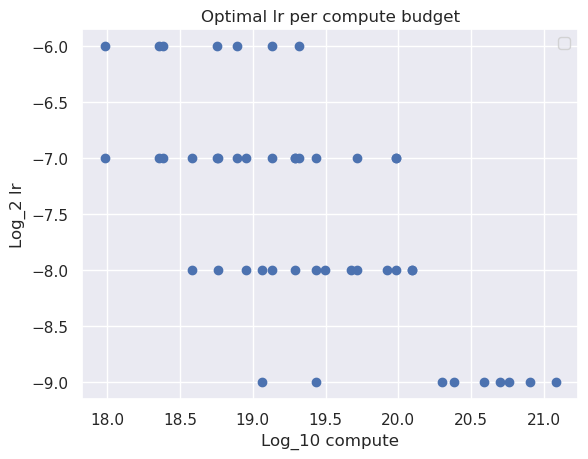

In [24]:
# old_fit = lr_pred_fit[500:4500]
# plt.plot([math.log(val, 10) for val in compute_grid[500:4500]], old_fit, label = "old fit", color = "red")
# plt.plot([math.log(val, 10) for val in compute_grid[500:4500]], lr_pred_fit[500:4500], label = "new fit", color = "green")
plt.scatter(new_comp, new_lr)
# plt.scatter(computes, lrs)
plt.title("Optimal lr per compute budget")
plt.xlabel("Log_10 compute")
plt.ylabel("Log_2 lr")
plt.legend()
plt.show()

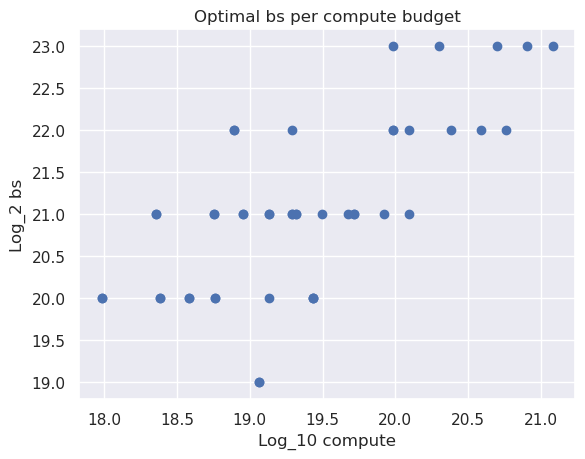

In [25]:
plt.scatter(new_comp, new_bs)
# plt.scatter(computes, bathces)
plt.title("Optimal bs per compute budget")
plt.xlabel("Log_10 compute")
plt.ylabel("Log_2 bs")
plt.show()

/tmp/ipykernel_1587483/2542982377.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


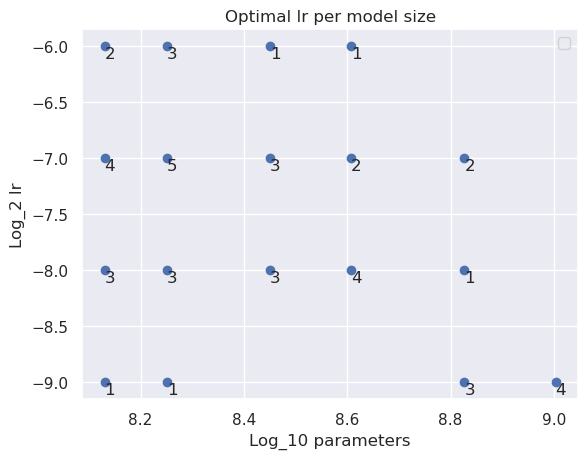

In [26]:
from collections import Counter
cnts = Counter(list(zip(new_models, new_lr)))

new_models_plot = [x[0] for x in cnts.keys()]
new_lr_plot = [x[1] for x in cnts.keys()]

plt.scatter(new_models_plot, new_lr_plot)

for (ms, lr), cnt in cnts.items():
    plt.text(ms, lr, str(cnt), fontsize=12, ha='left', va='top')

plt.title("Optimal lr per model size")
plt.xlabel("Log_10 parameters")
plt.ylabel("Log_2 lr")
plt.legend()
plt.show()

/tmp/ipykernel_1587483/3601840386.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


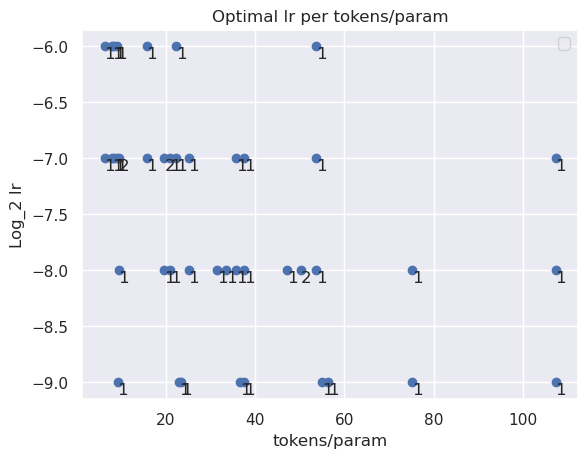

In [27]:


cnts = Counter(list(zip([x for x in new_data_mults_lr], [x for x in new_lr])))

# cnts = {k: v for k, v in cnts.items() if k[0] < 4000}

new_models_plot = [x[0] for x in cnts.keys()]
new_lr_plot = [x[1] for x in cnts.keys()]

plt.scatter(new_models_plot, new_lr_plot)

for (ms, lr), cnt in cnts.items():
    plt.text(ms, lr, str(cnt), fontsize=12, ha='left', va='top')

plt.title("Optimal lr per tokens/param")
plt.xlabel("tokens/param")
plt.ylabel("Log_2 lr")
plt.legend()
plt.show()

In [28]:
def linreg(X, y):
    return np.linalg.inv(X.T @ X) @ X.T @ y

def lin_pred(beta, X):
    return X @ beta

In [29]:
total_120b = 123.401 * 10**9
active_120b = 11.146 * 10**9

total_gigaseek_k2 = 1004.411 * 10**9
active_gigaseek_k2 = 43.982 * 10**9

In [43]:


X_compute_bs = np.array(new_comp)
X_compute_bs = np.stack([np.ones(len(X_compute_bs)), X_compute_bs, np.array(new_data_mults_bs)]).T
# X_compute_bs = np.stack([np.ones(len(X_compute_bs)), X_compute_bs]).T


X_compute_lr = np.array(new_comp)
# X_compute_lr = np.array(new_tokens)
X_compute_lr = np.stack([np.ones(len(X_compute_lr)), X_compute_lr, np.array(new_models), np.array(new_data_mults_lr)]).T
# y_batches = np.array(bathces)
# y_lrs = np.array(lrs)

# y_batches_log = np.array([math.log(x, 2) for x in bathces])
y_batches_log = np.array(new_bs)
# y_lrs_log = np.array([math.log(x, 2) for x in lrs])
y_lrs_log = np.array(new_lr)



beta_compute_lr = linreg(X_compute_lr, y_lrs_log)
beta_compute_bs = linreg(X_compute_bs, y_batches_log)

In [44]:
beta_compute_lr

array([ 4.28402101e+00, -1.76650263e+00,  2.64390329e+00,  1.47281038e-03])

In [45]:
beta_compute_bs

array([ 1.64350469e+00,  1.01844501e+00, -1.65788575e-04])

In [46]:
X_120b_moe_500B_lr = np.array([1, math.log(69341675520 * 500 * 10**9, 10), math.log(total_120b if use_total_model_size else active_120b, base_log_params), fn_tokens_params_lr(500 * 10**9, (total_120b if use_total_token_per_param else active_120b))])
X_120b_moe_500B_bs = np.array([1, math.log(69341675520 * 500 * 10**9, 10), fn_tokens_params_bs(500 * 10**9, (total_120b if use_total_token_per_param else active_120b))])


print(f"X_120b_moe_500B lr pred: {round(2 ** lin_pred(beta_compute_lr, X_120b_moe_500B_lr), 5)}, bs pred: {int(2 ** lin_pred(beta_compute_bs, X_120b_moe_500B_bs))}")



X_gigaseek_k2_moe_300B_lr = np.array([1, math.log(222854381568 * 300 * 10**9, 10), math.log(total_gigaseek_k2 if use_total_model_size else active_gigaseek_k2, base_log_params), fn_tokens_params_lr(300 * 10**9, (total_gigaseek_k2 if use_total_token_per_param else active_gigaseek_k2))])
X_gigaseek_k2_moe_300B_bs = np.array([1, math.log(222854381568 * 300 * 10**9, 10), fn_tokens_params_bs(300 * 10**9, (total_gigaseek_k2 if use_total_token_per_param else active_gigaseek_k2))])

print(f"X_gigaseek_k2_moe_300B lr pred: {round(2 ** lin_pred(beta_compute_lr, X_gigaseek_k2_moe_300B_lr), 5)}, bs pred: {int(2 ** lin_pred(beta_compute_bs, X_gigaseek_k2_moe_300B_bs))}")





X_gigaseek_k2_moe_1T_lr = np.array([1, math.log(222854381568 * 1000 * 10**9, 10), math.log(total_gigaseek_k2 if use_total_model_size else active_gigaseek_k2, base_log_params), fn_tokens_params_lr(300 * 10**9, (total_gigaseek_k2 if use_total_token_per_param else active_gigaseek_k2))])
X_gigaseek_k2_moe_1T_bs = np.array([1, math.log(222854381568 * 1000 * 10**9, 10), fn_tokens_params_bs(1000 * 10**9, (total_gigaseek_k2 if use_total_token_per_param else active_gigaseek_k2))])

print(f"X_gigaseek_k2_moe_1T lr pred: {round(2 ** lin_pred(beta_compute_lr, X_gigaseek_k2_moe_1T_lr), 5)}, bs pred: {int(2 ** lin_pred(beta_compute_bs, X_gigaseek_k2_moe_1T_bs))}")




X_gigaseek_k2_moe_15T_lr = np.array([1, math.log(222854381568 * 15000 * 10**9, 10), math.log(total_gigaseek_k2 if use_total_model_size else active_gigaseek_k2, base_log_params), fn_tokens_params_lr(300 * 10**9, (total_gigaseek_k2 if use_total_token_per_param else active_gigaseek_k2))])
X_gigaseek_k2_moe_15T_bs = np.array([1, math.log(222854381568 * 15000 * 10**9, 10), fn_tokens_params_bs(15000 * 10**9, (total_gigaseek_k2 if use_total_token_per_param else active_gigaseek_k2))])

print(f"X_gigaseek_k2_moe_15T lr pred: {round(2 ** lin_pred(beta_compute_lr, X_gigaseek_k2_moe_15T_lr), 5)}, bs pred: {int(2 ** lin_pred(beta_compute_bs, X_gigaseek_k2_moe_15T_bs))}")



X_120b_moe_500B lr pred: 0.002, bs pred: 25367835
X_gigaseek_k2_moe_300B lr pred: 0.0042, bs pred: 31083428
X_gigaseek_k2_moe_1T lr pred: 0.00221, bs pred: 44956177
X_gigaseek_k2_moe_15T lr pred: 0.00052, bs pred: 100525698


/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


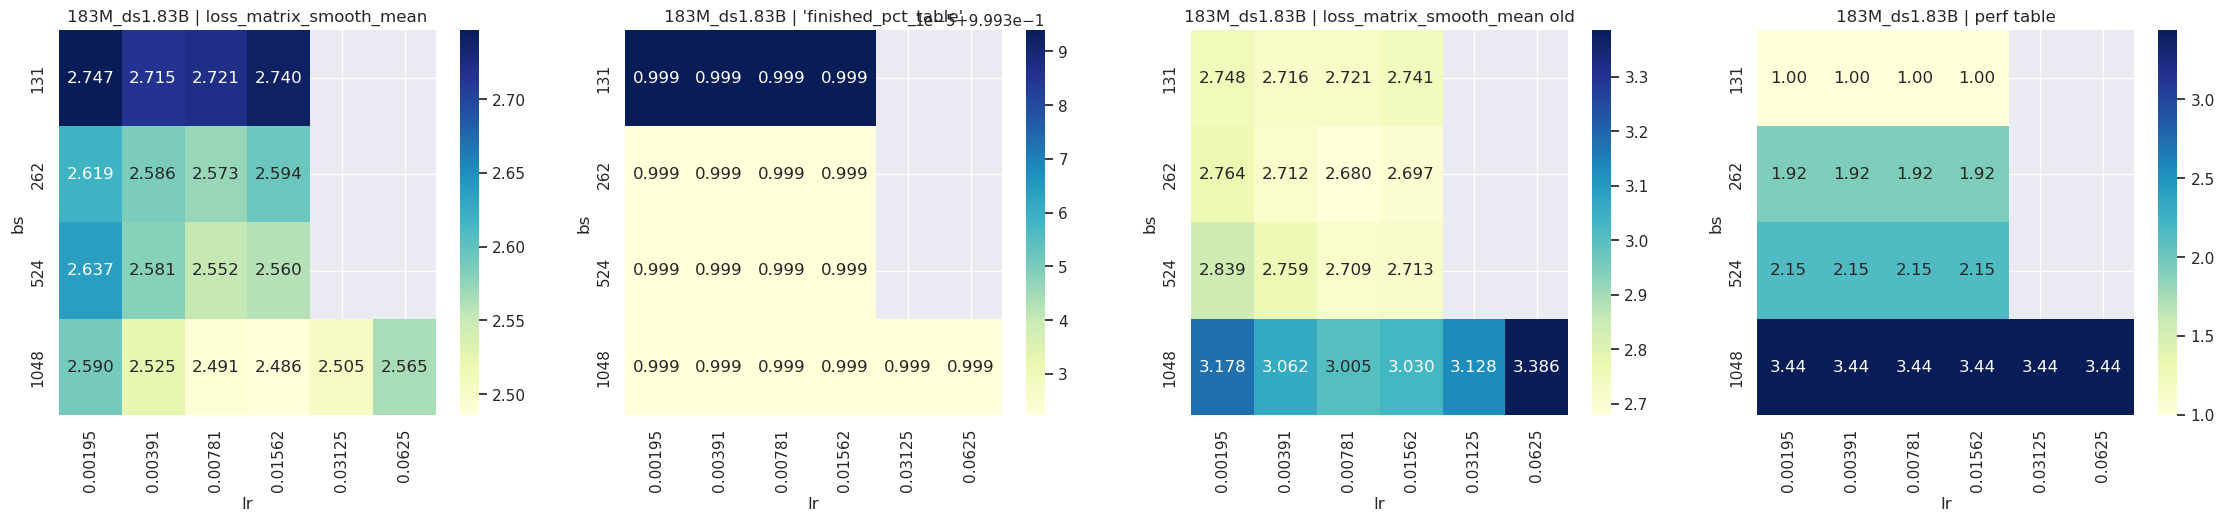

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


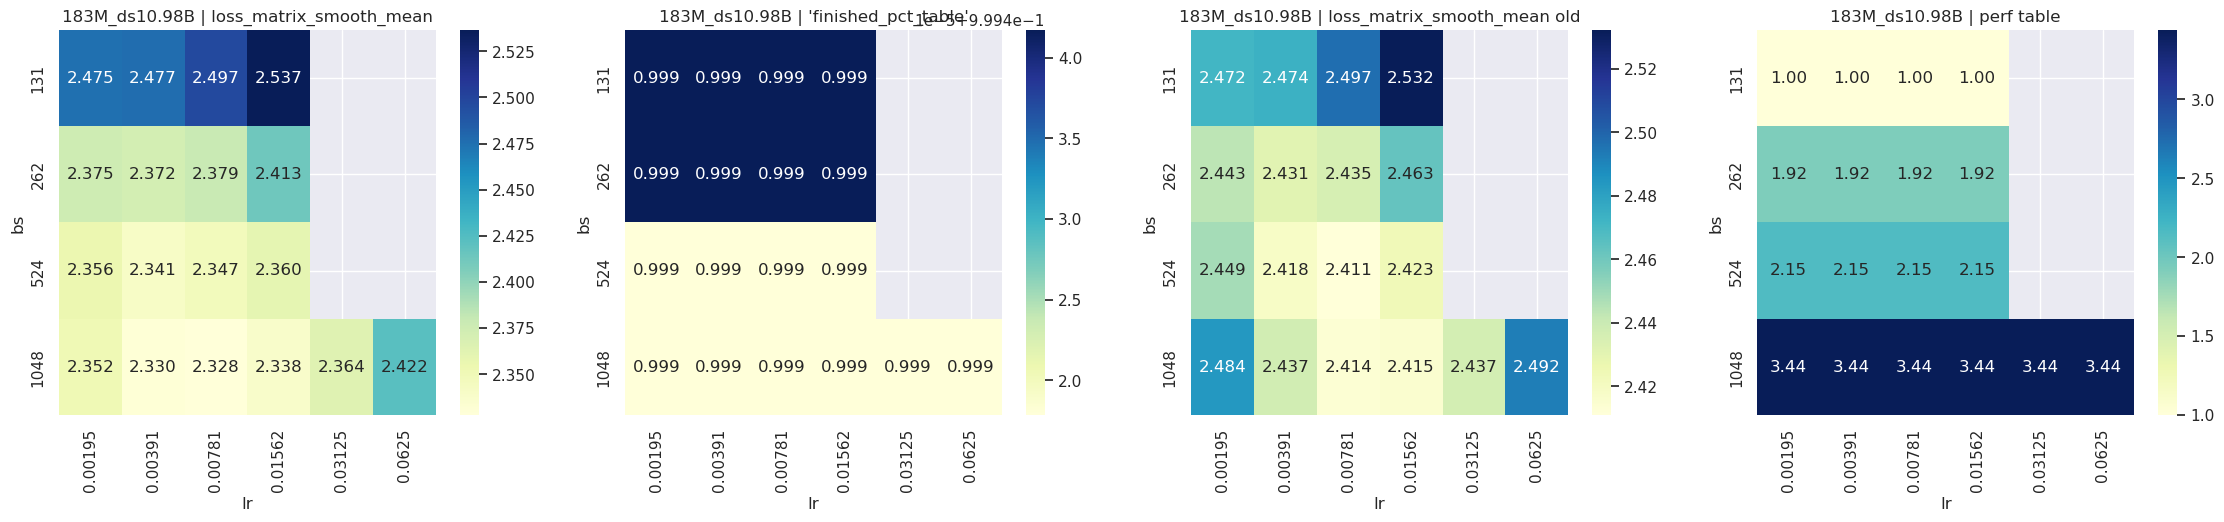

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


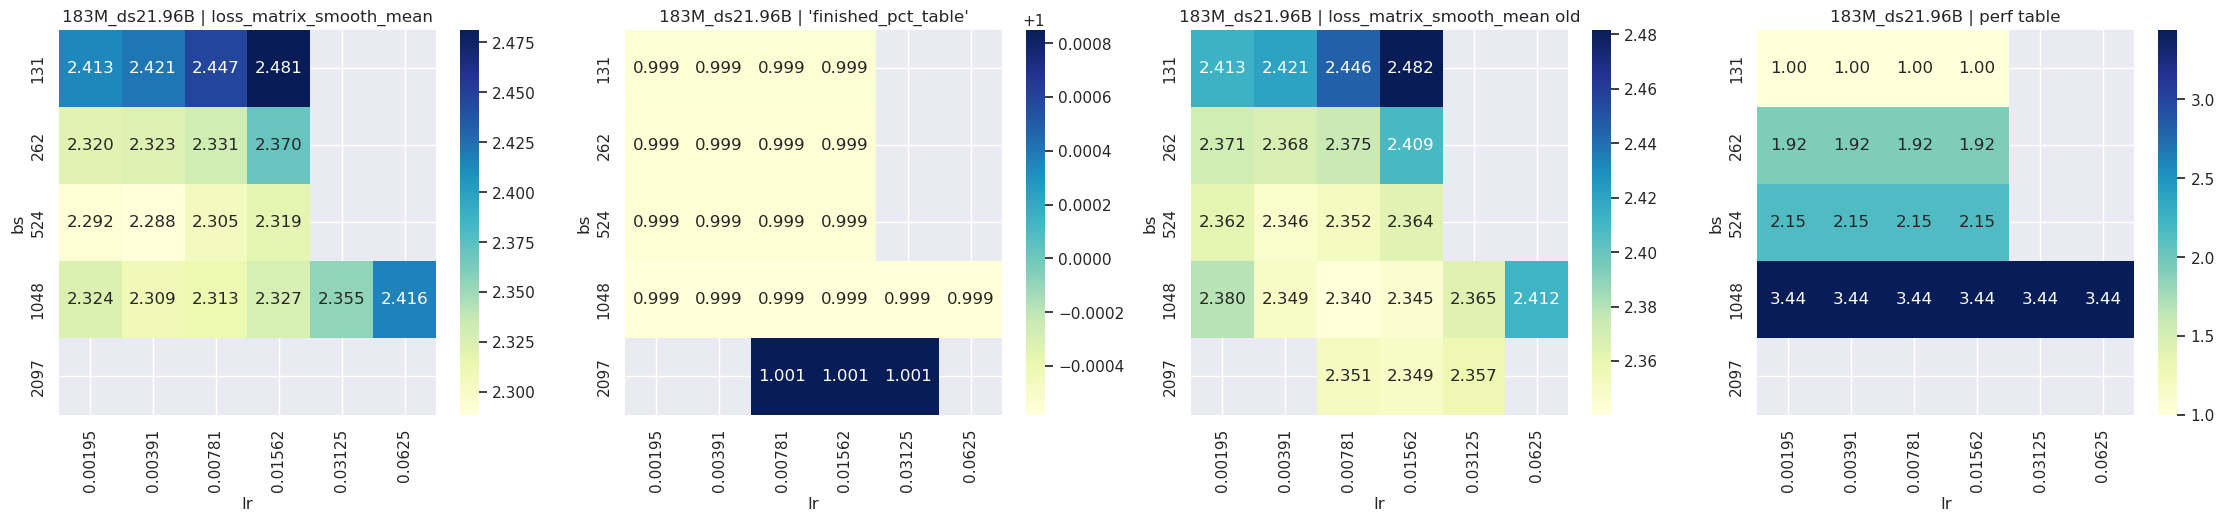

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


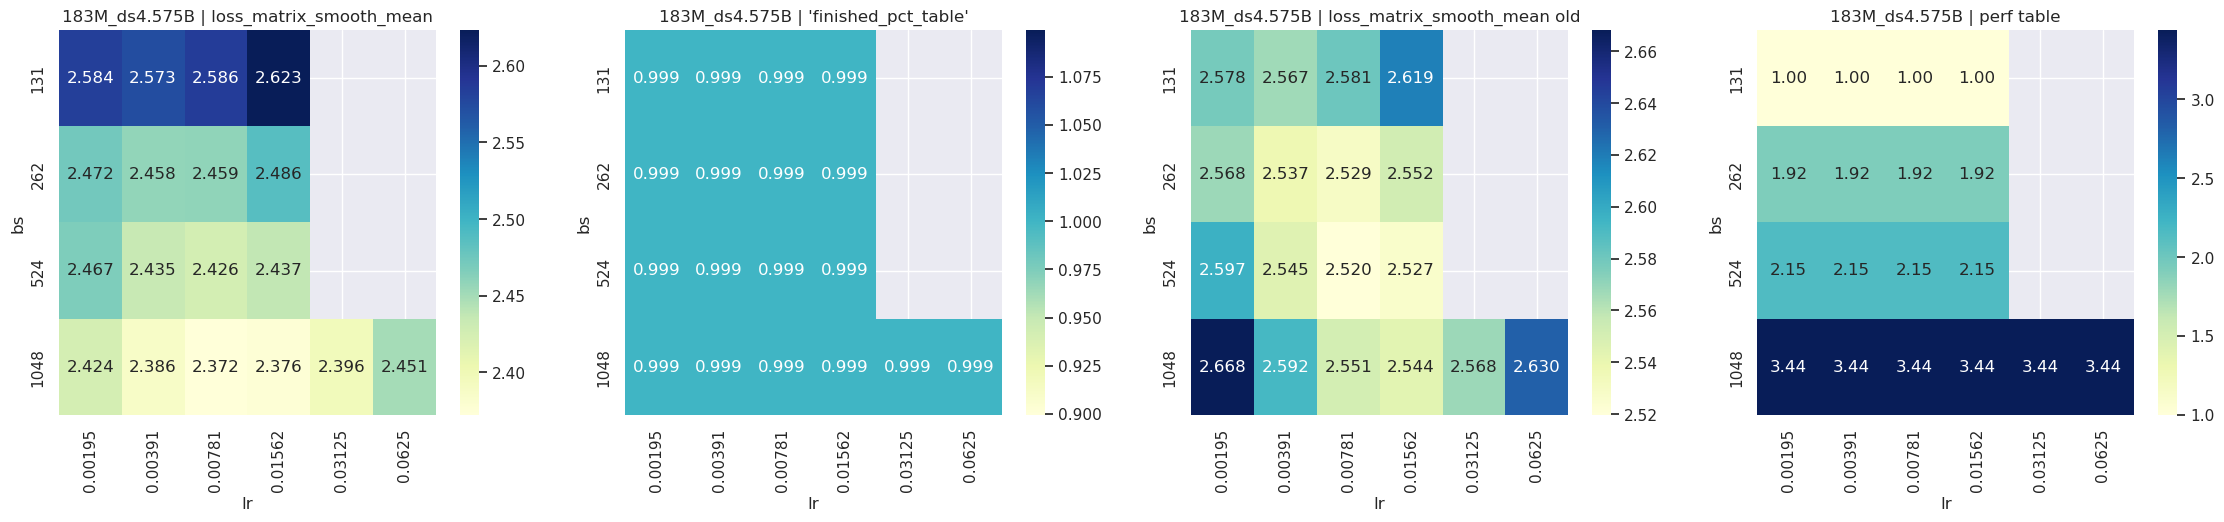

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


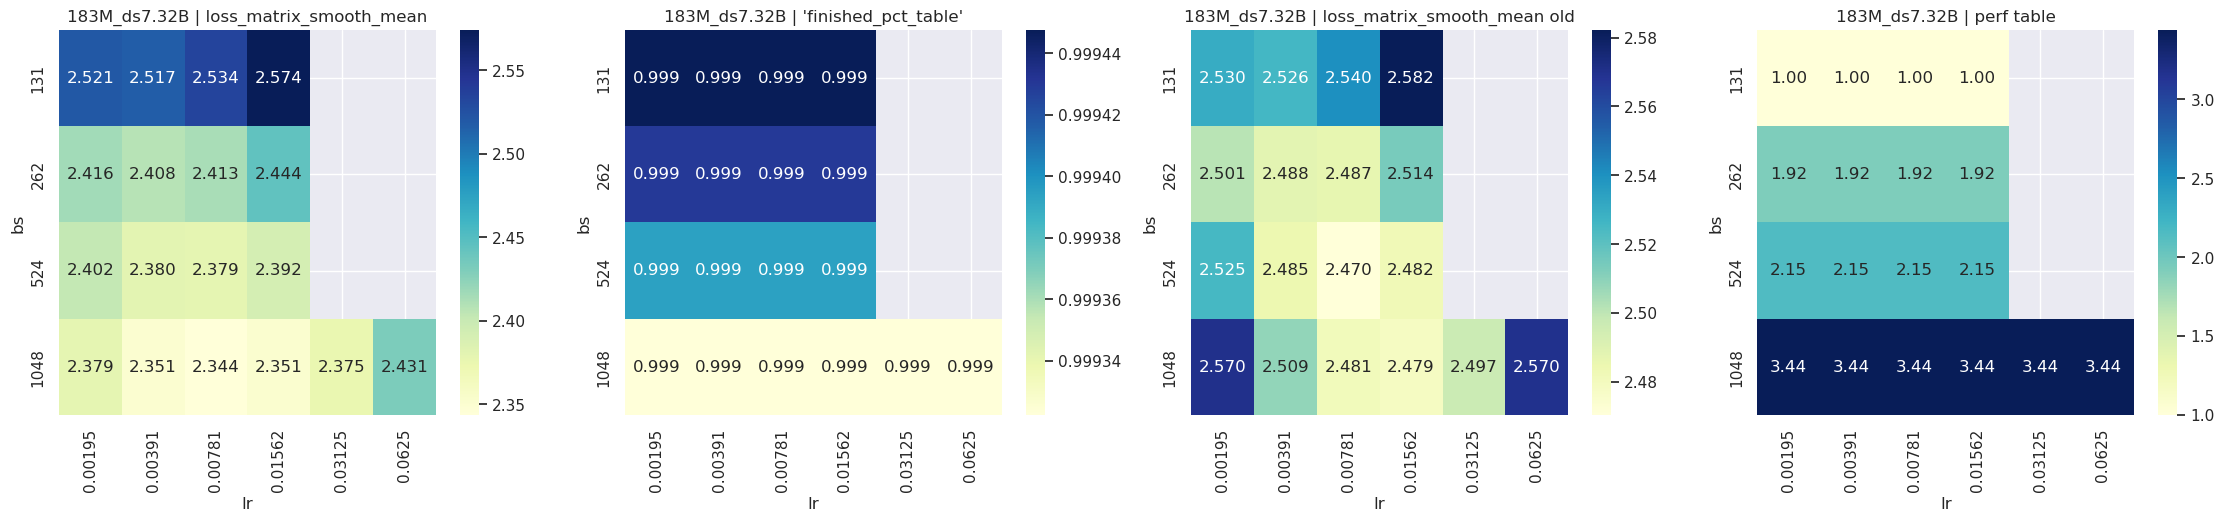

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


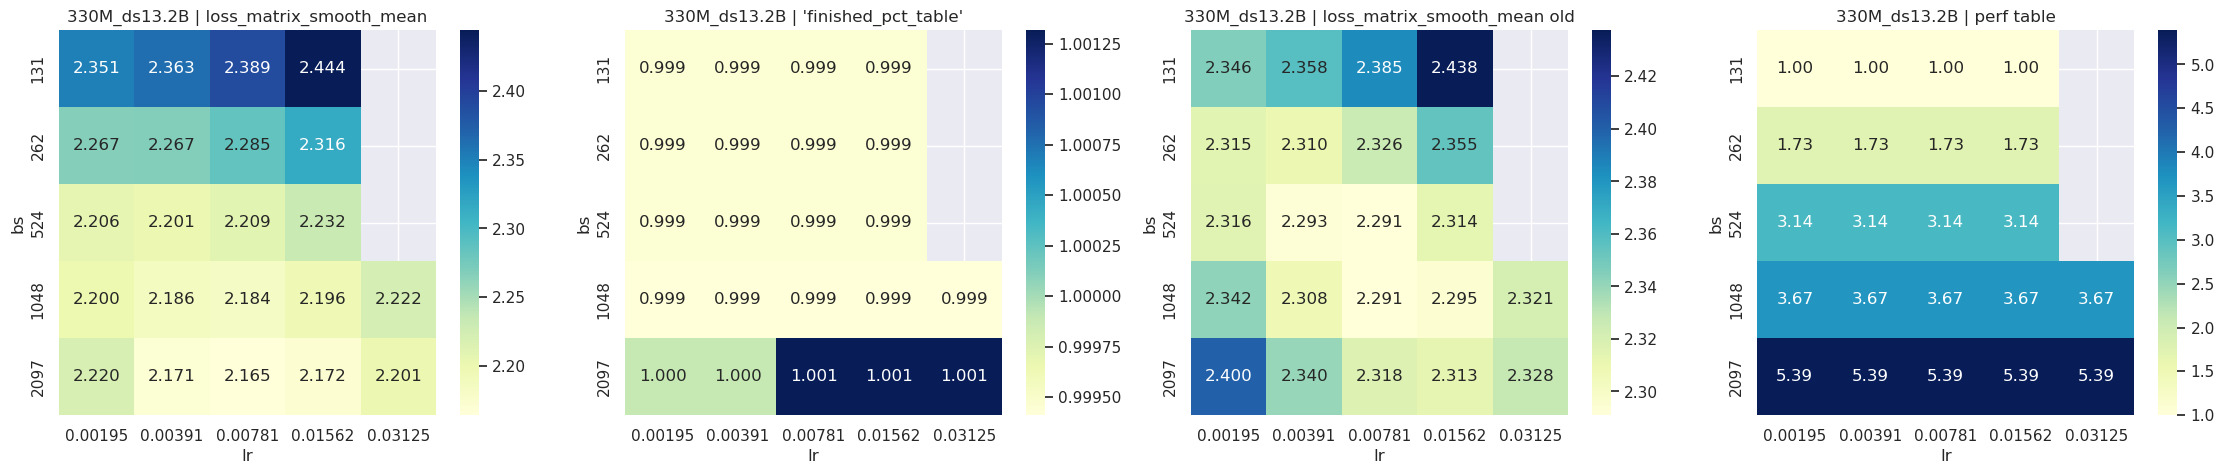

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


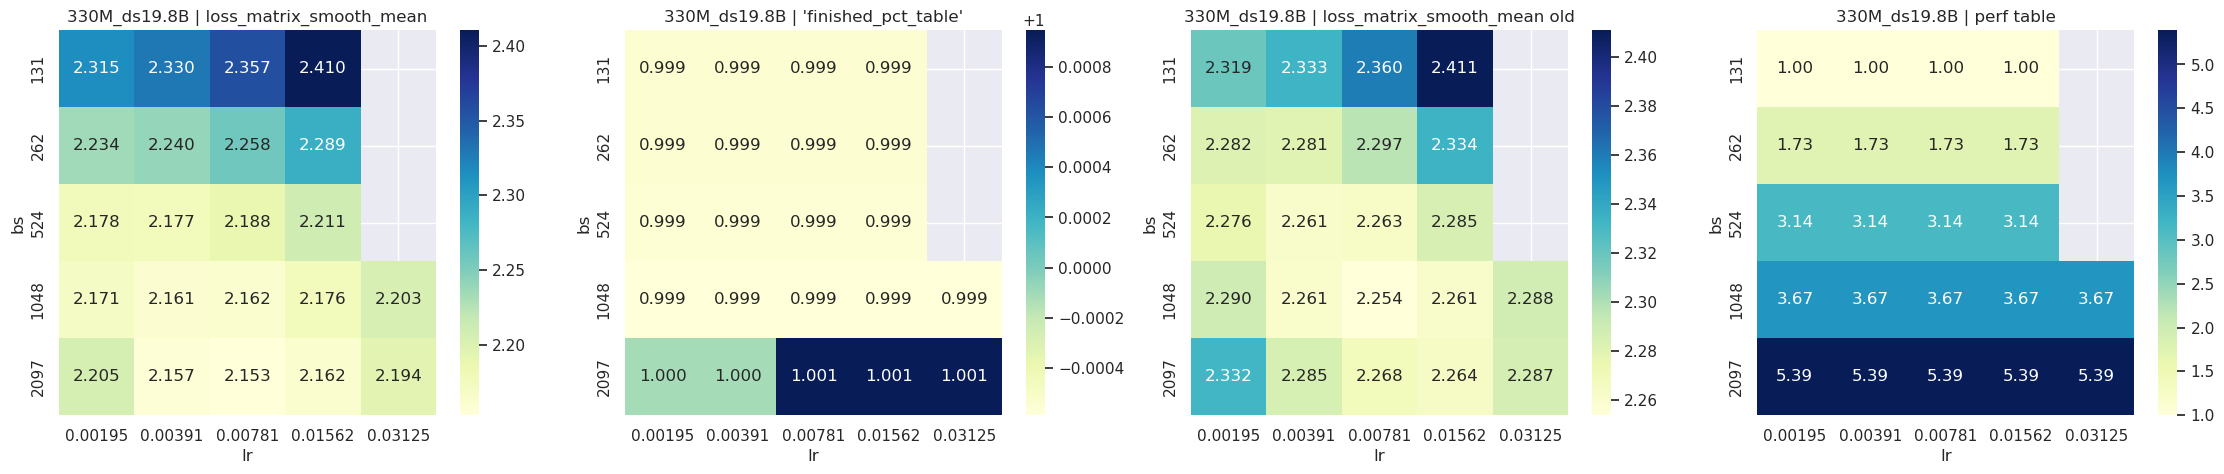

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


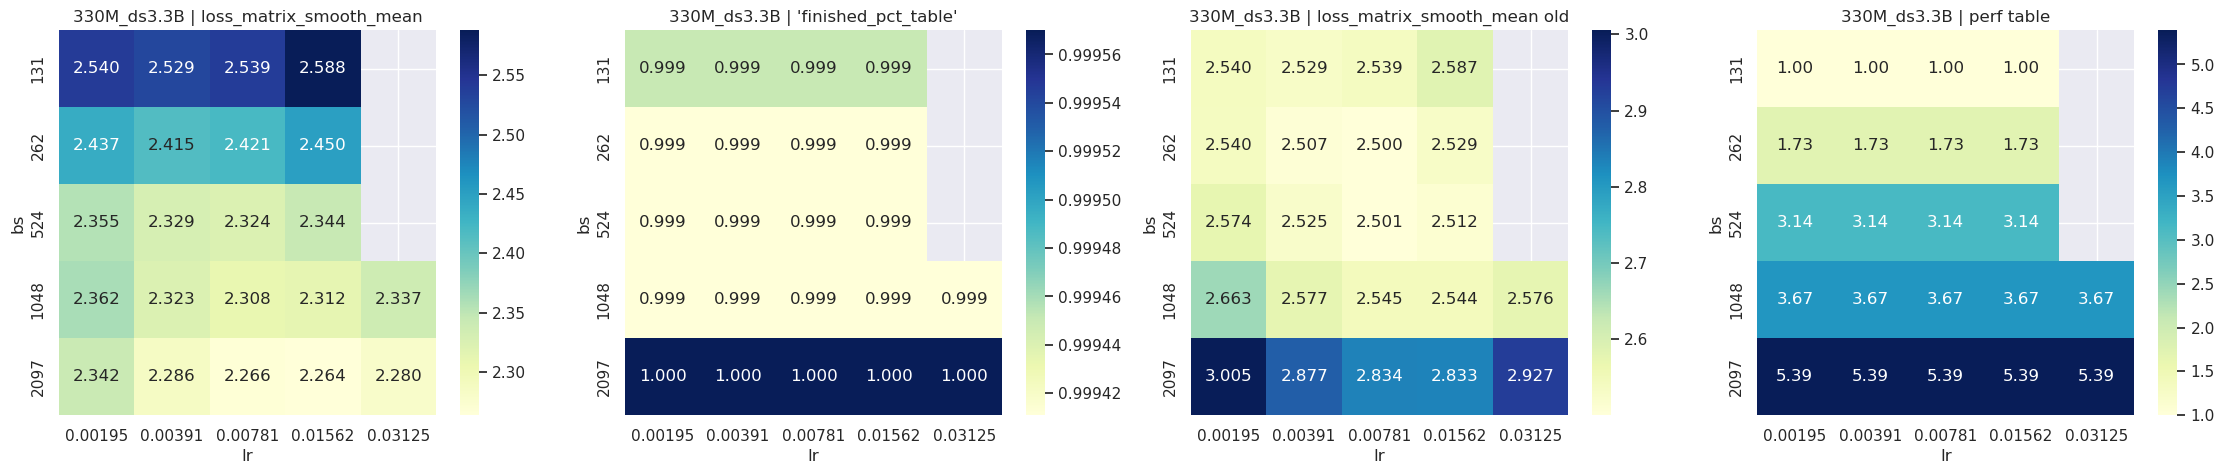

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


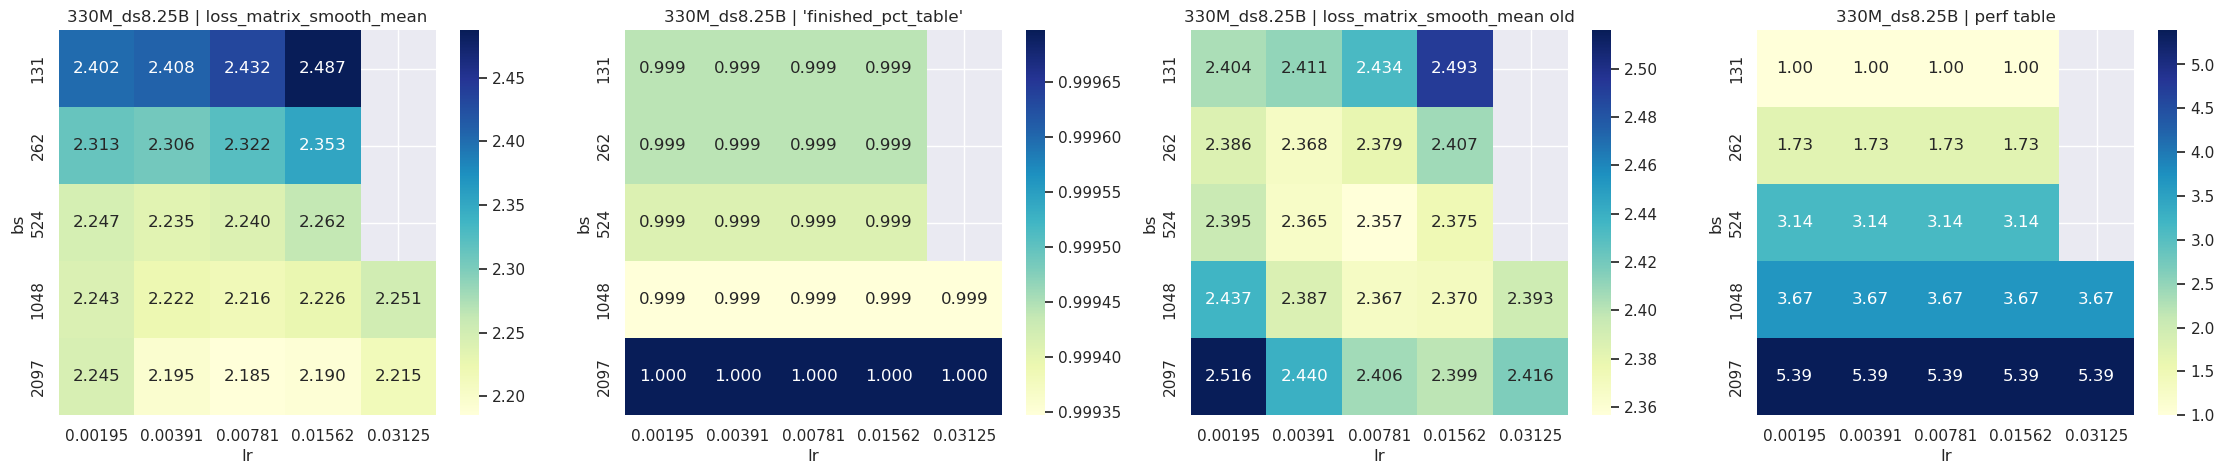

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


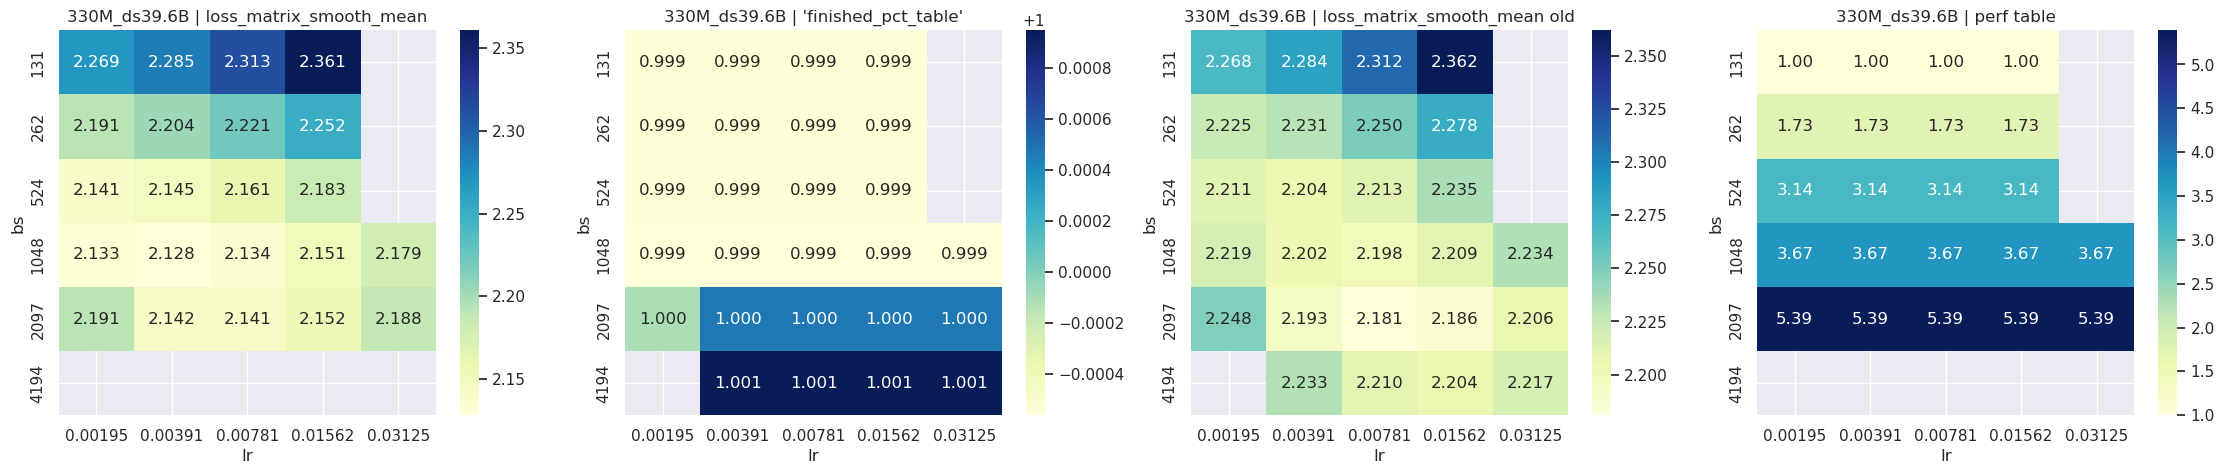

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


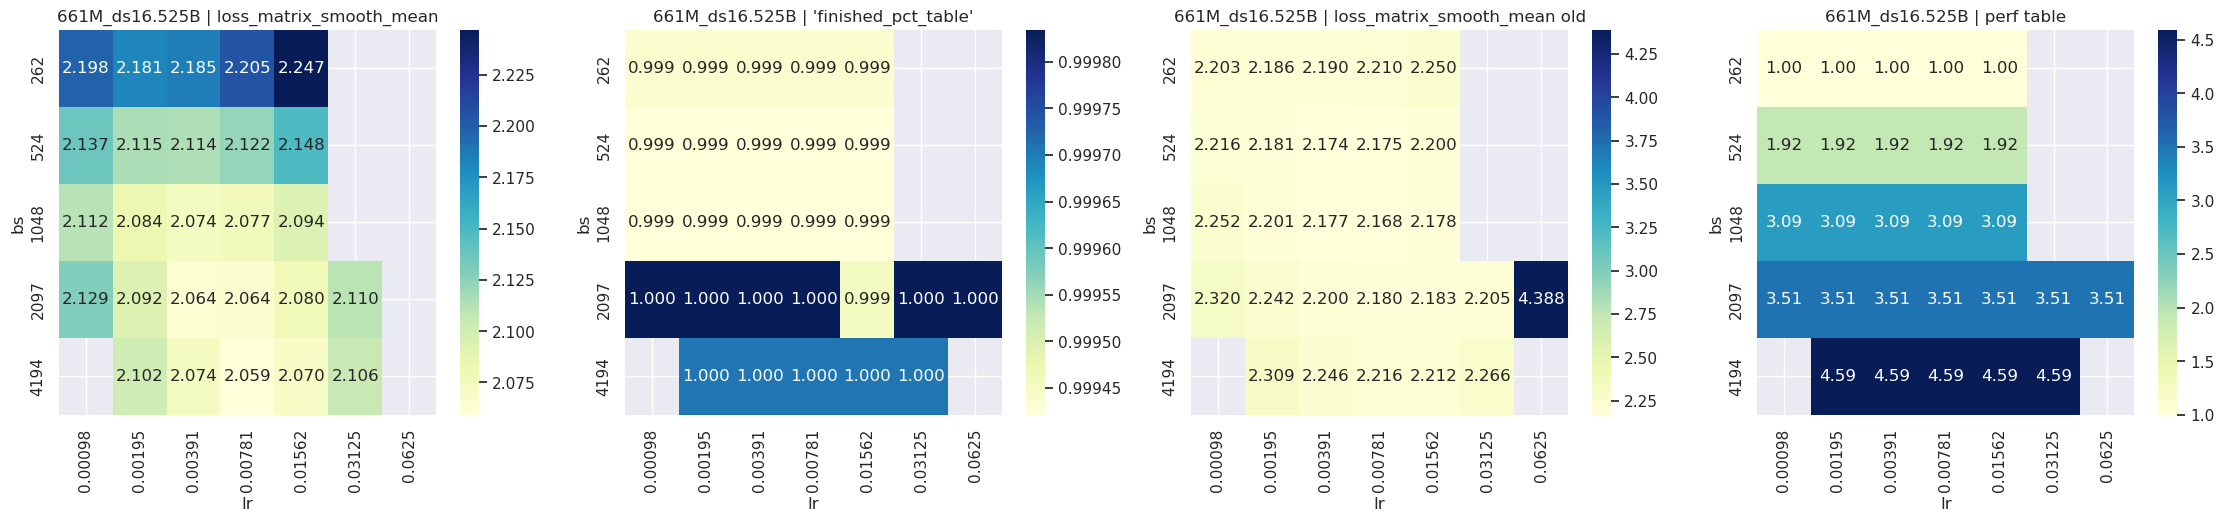

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


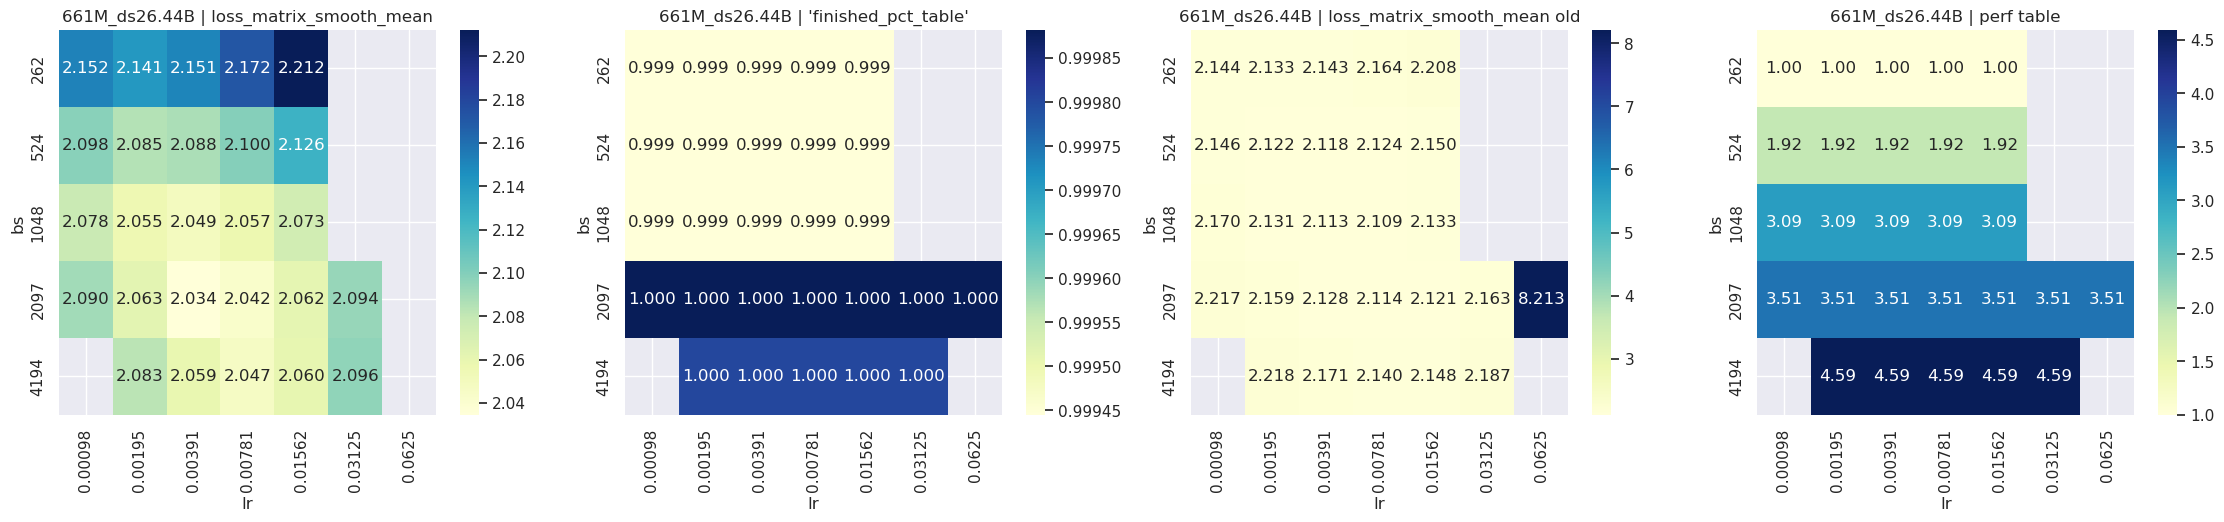

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


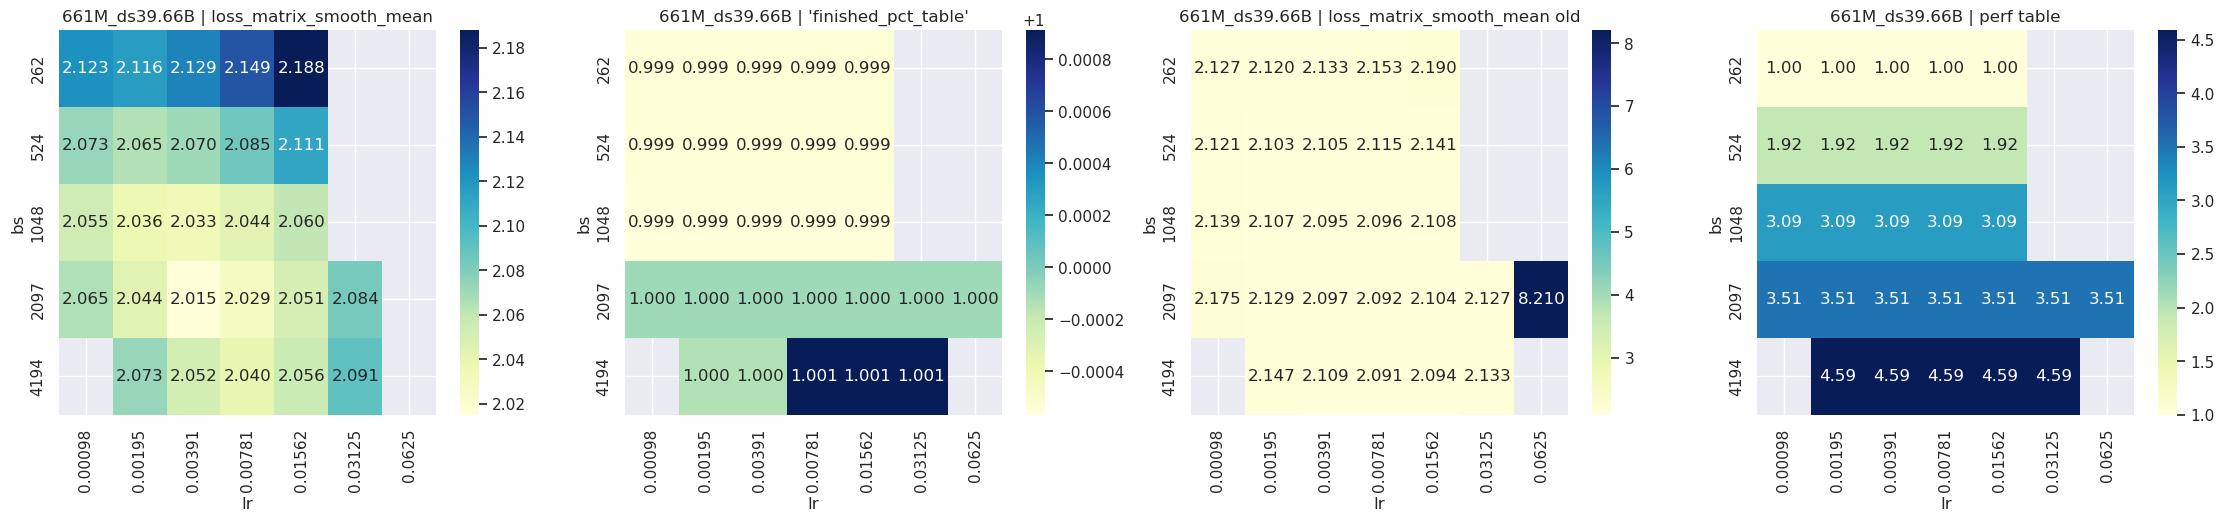

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


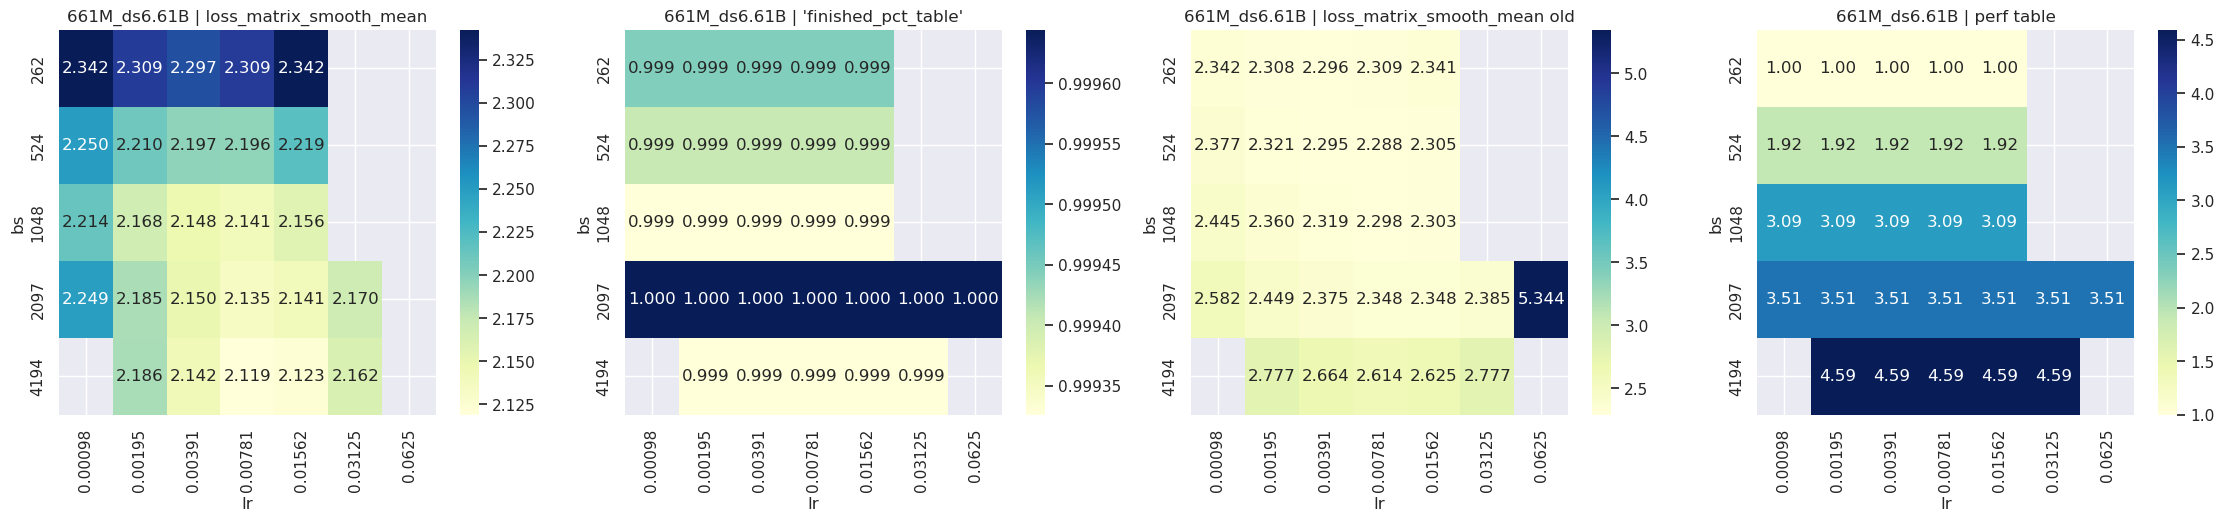

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


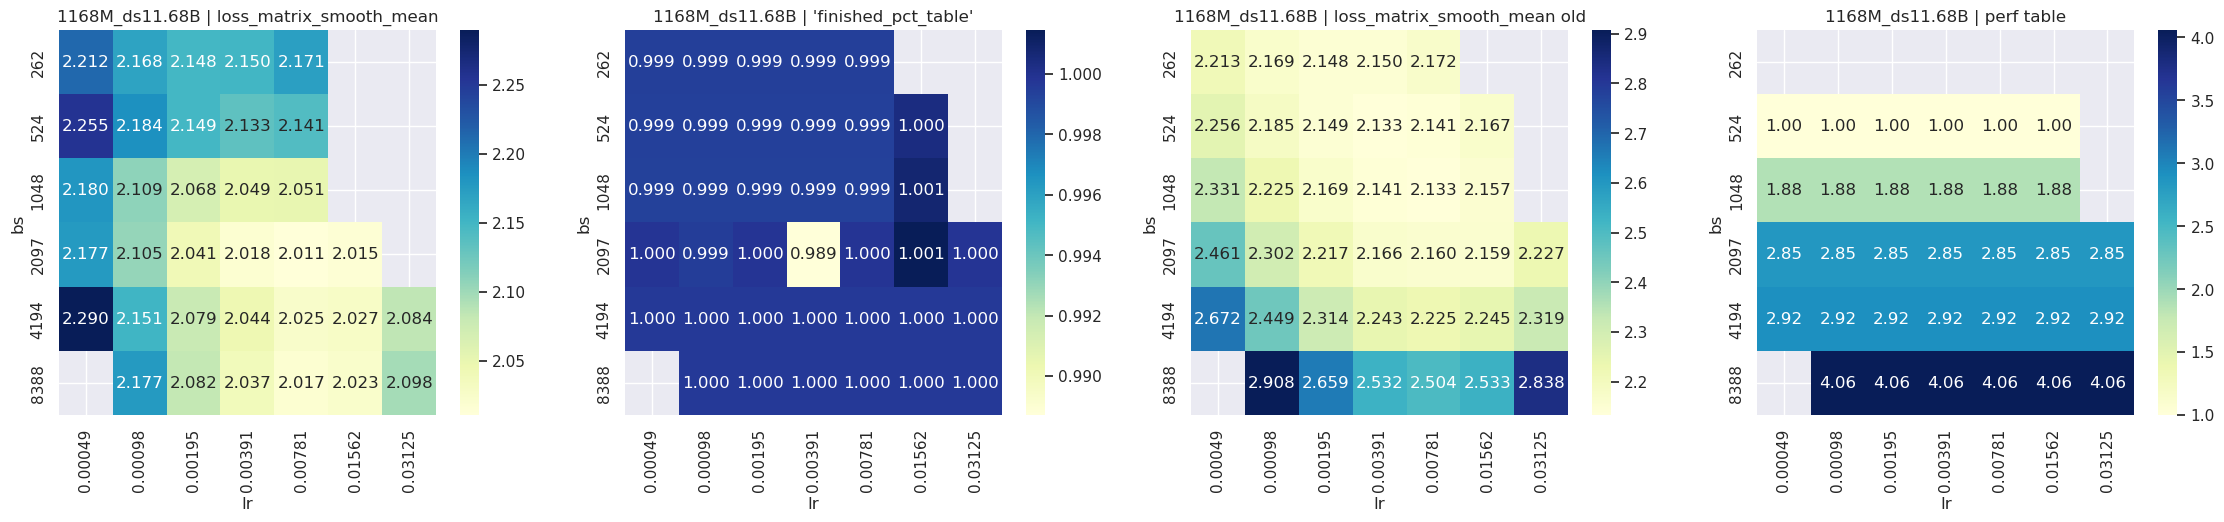

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


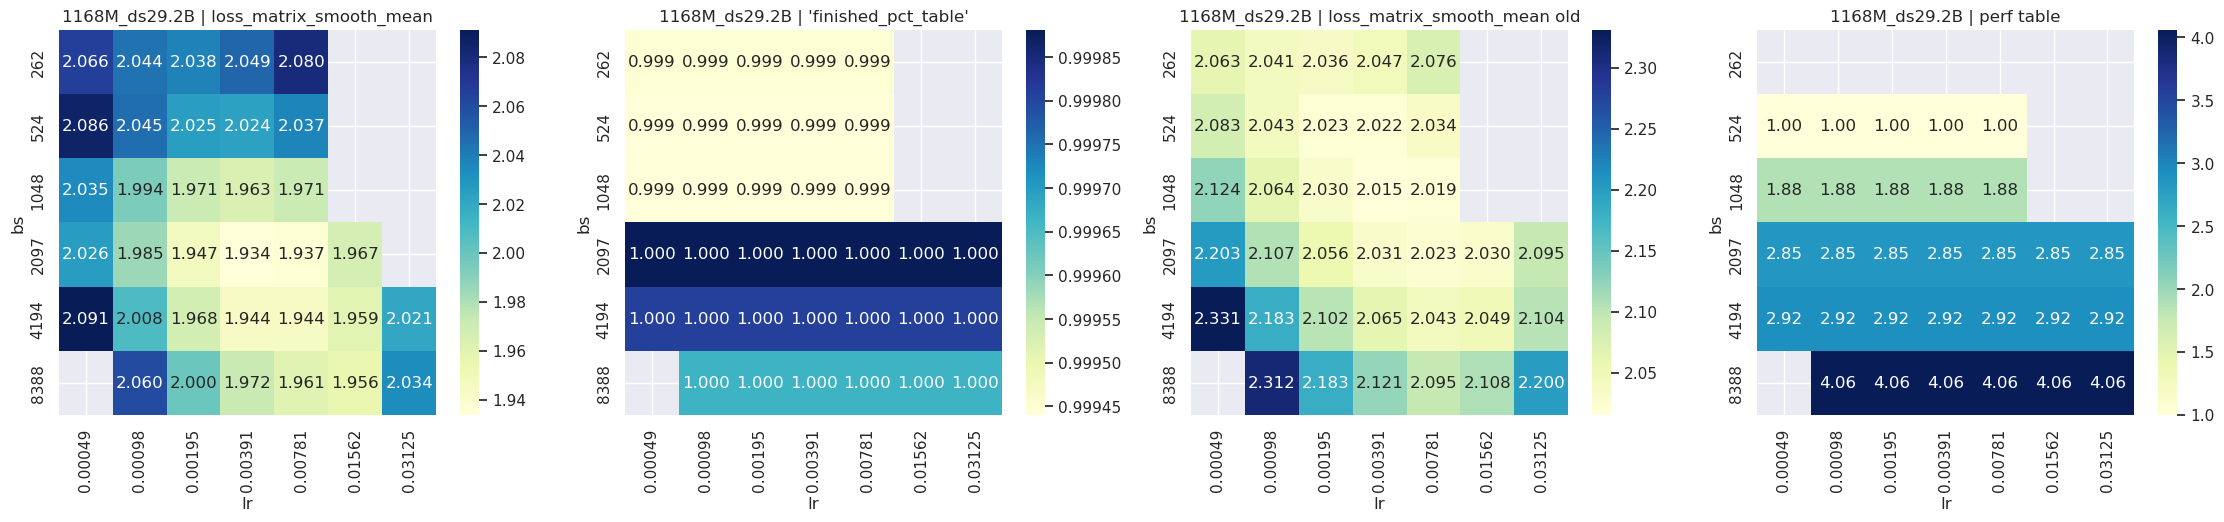

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


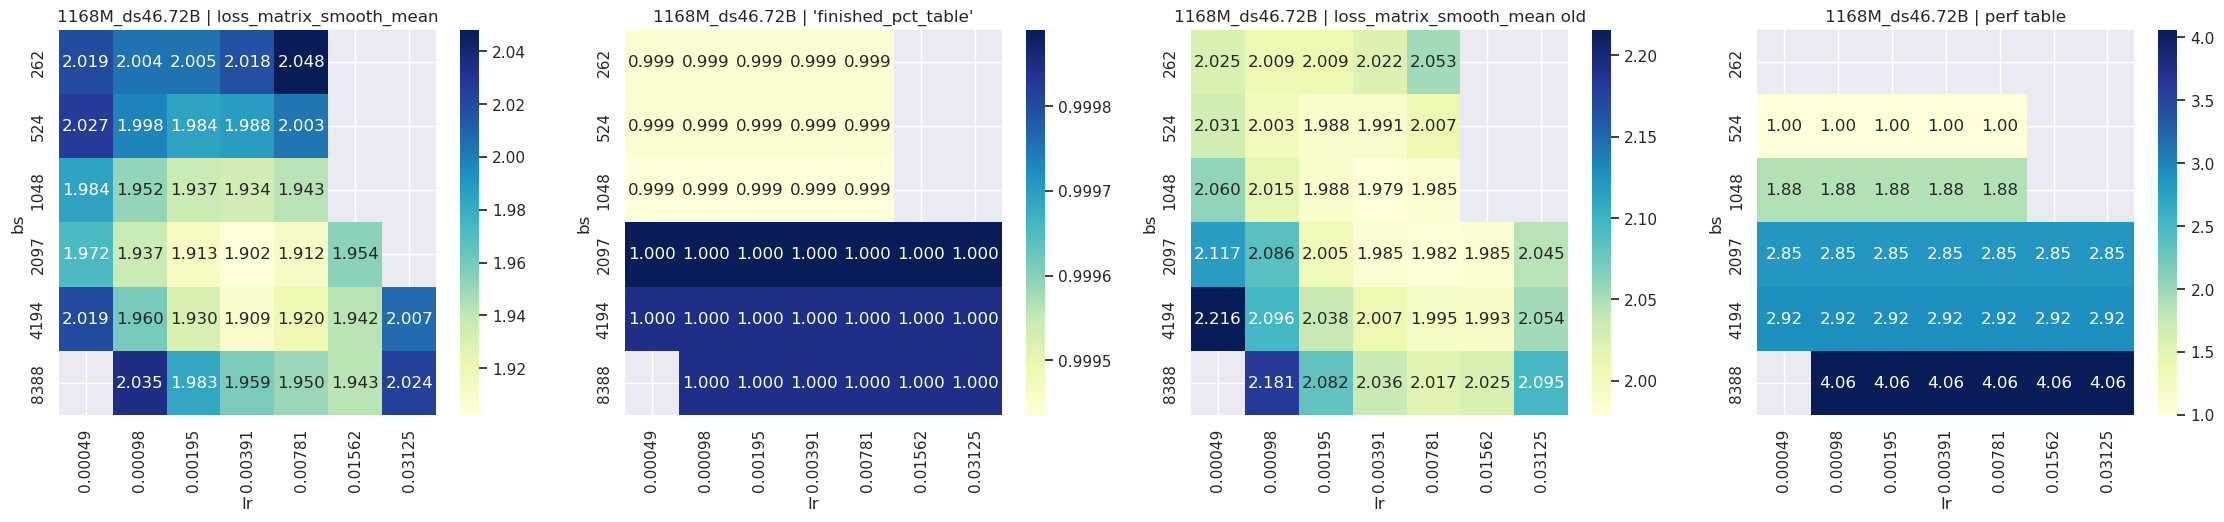

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


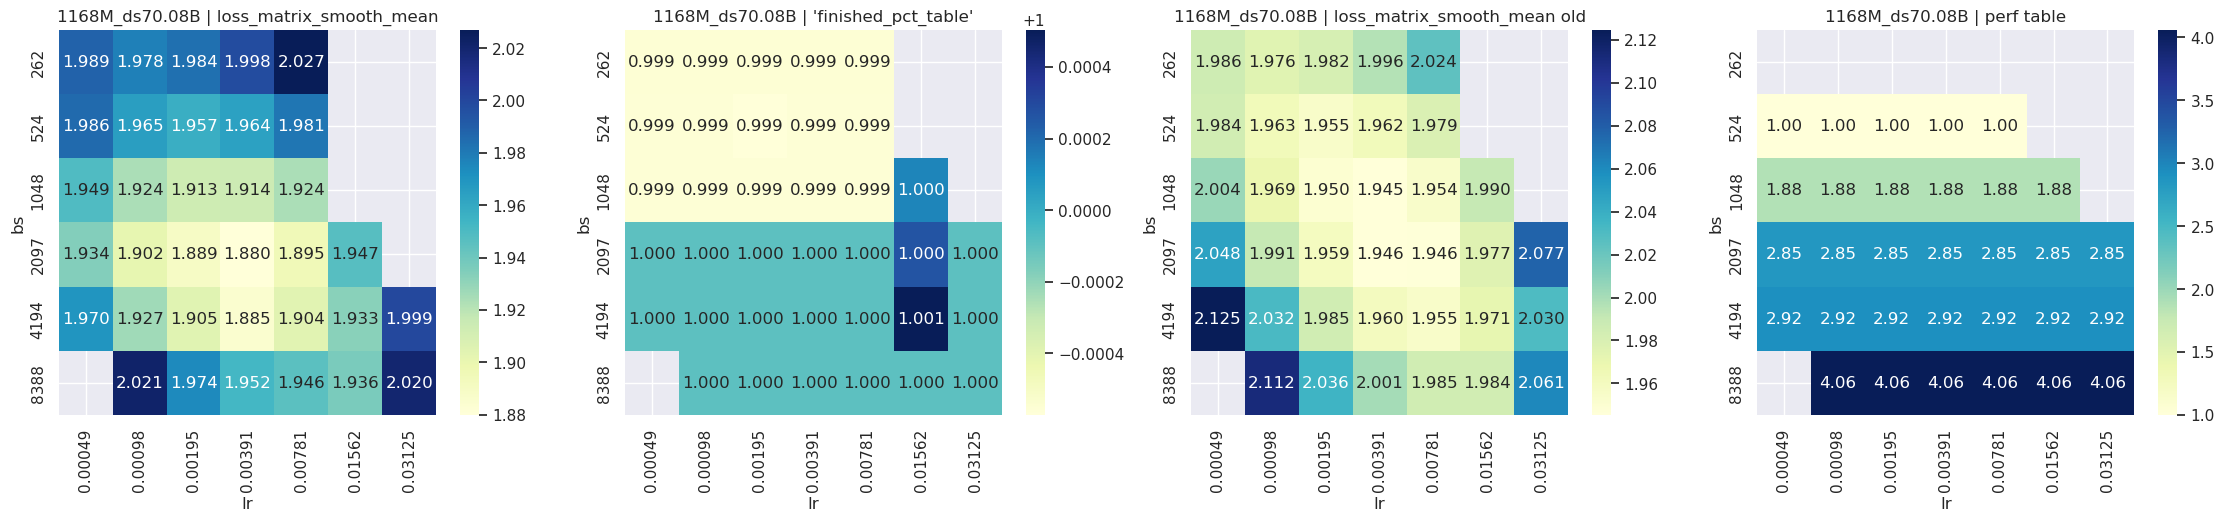

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


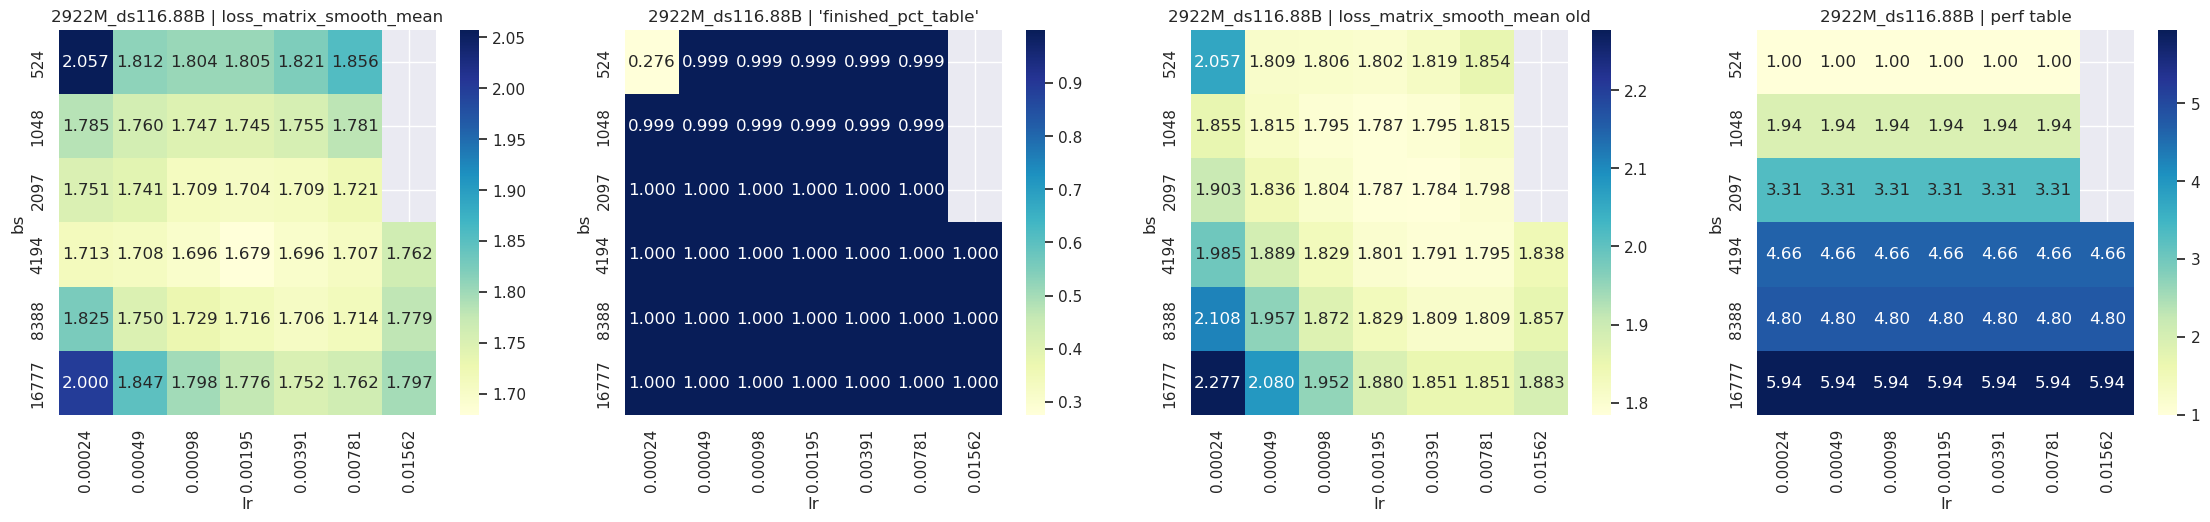

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


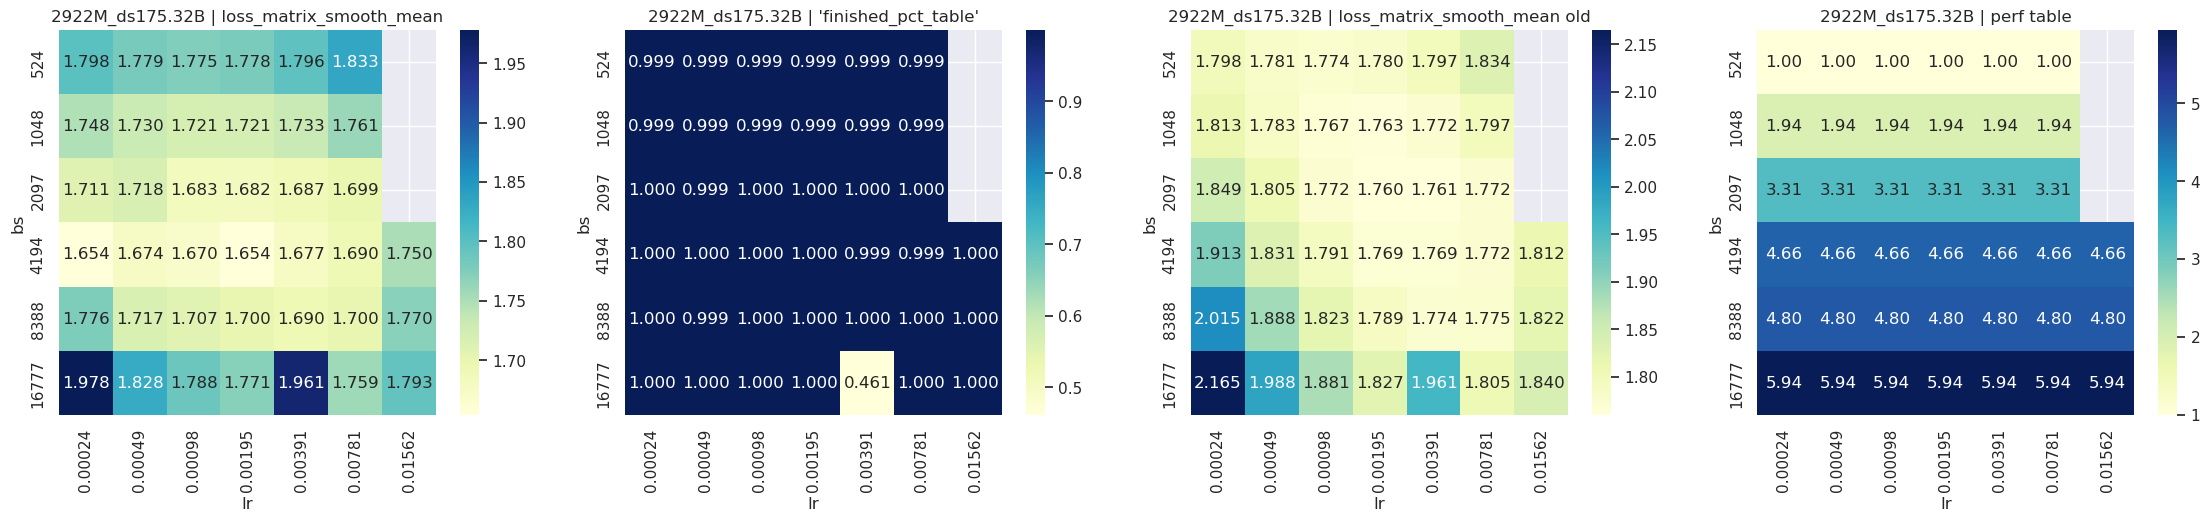

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


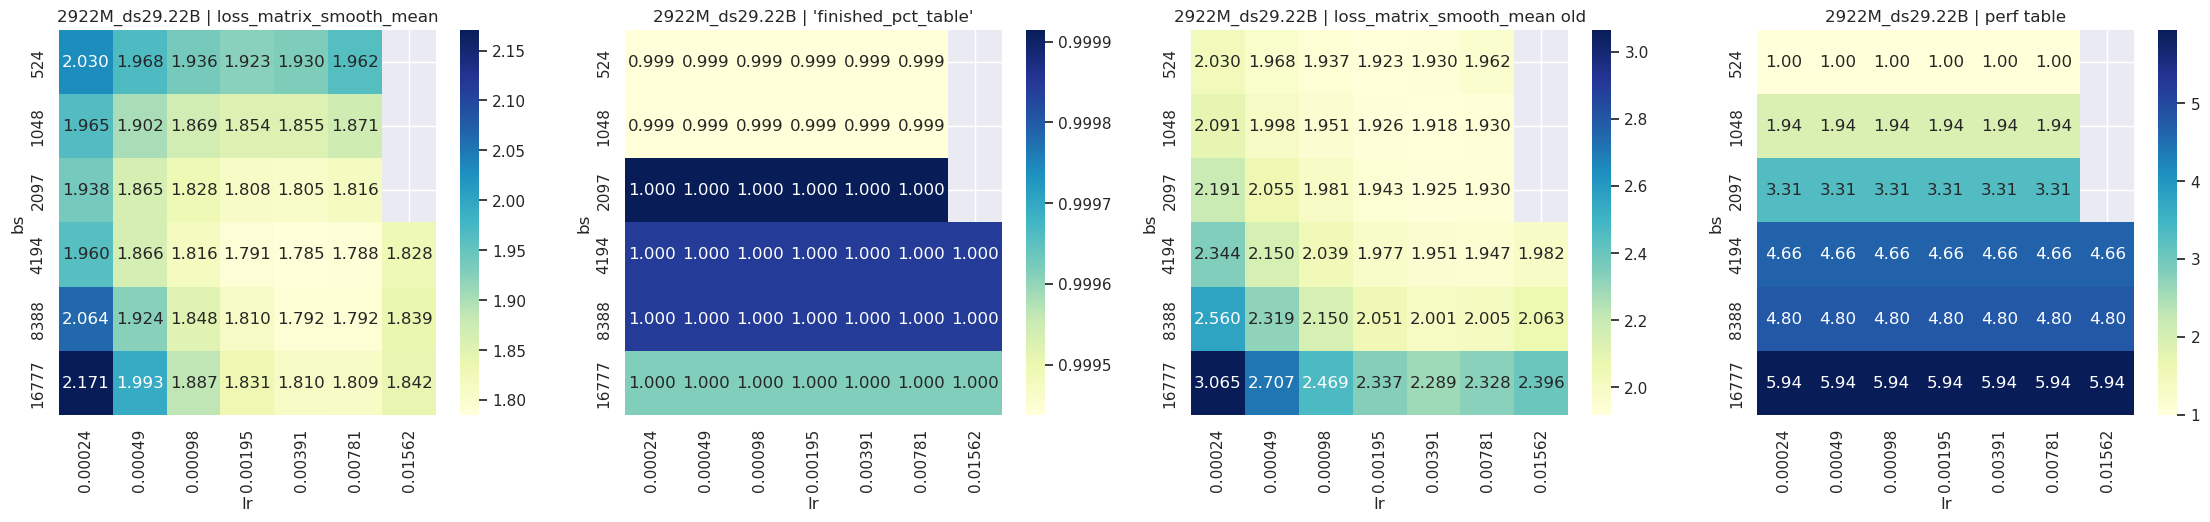

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


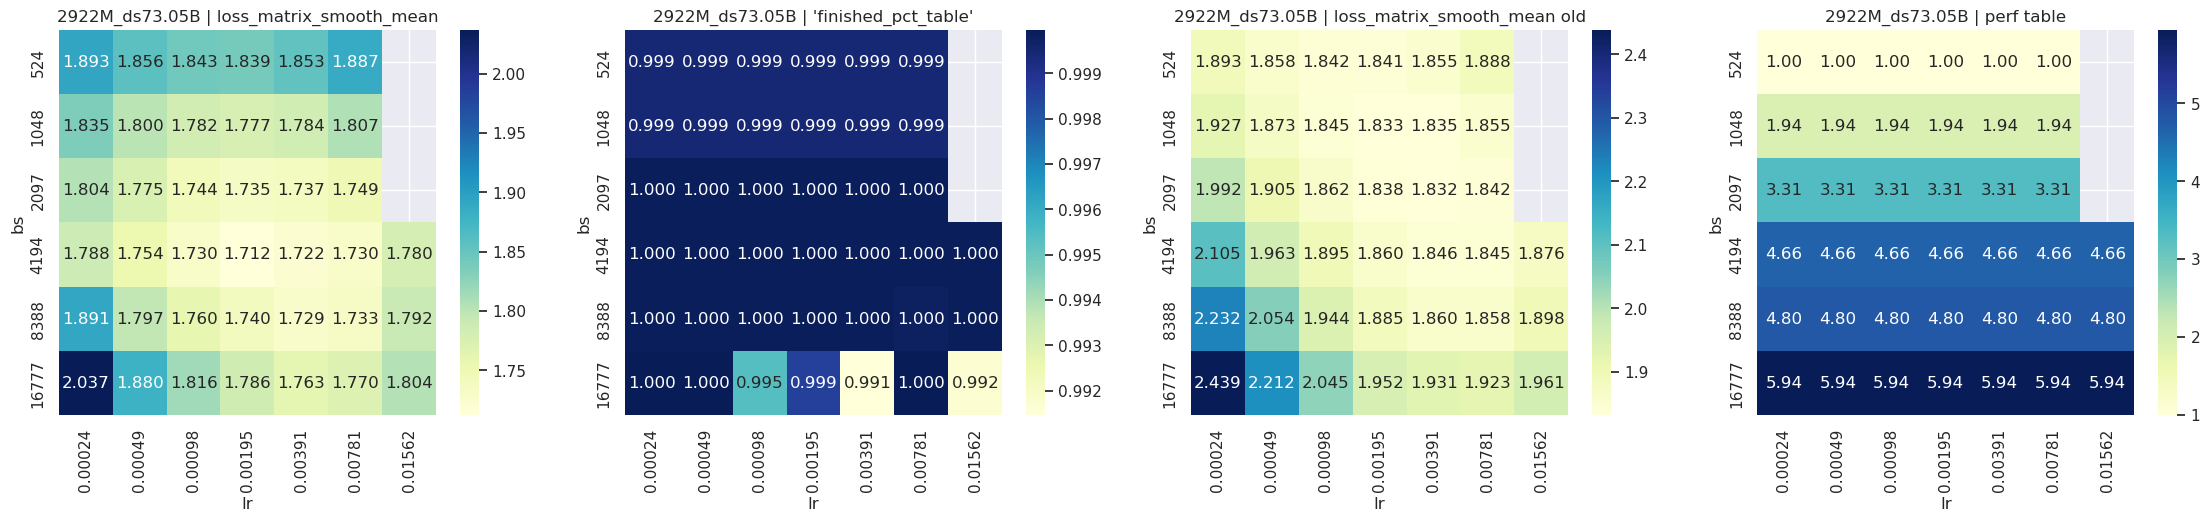

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


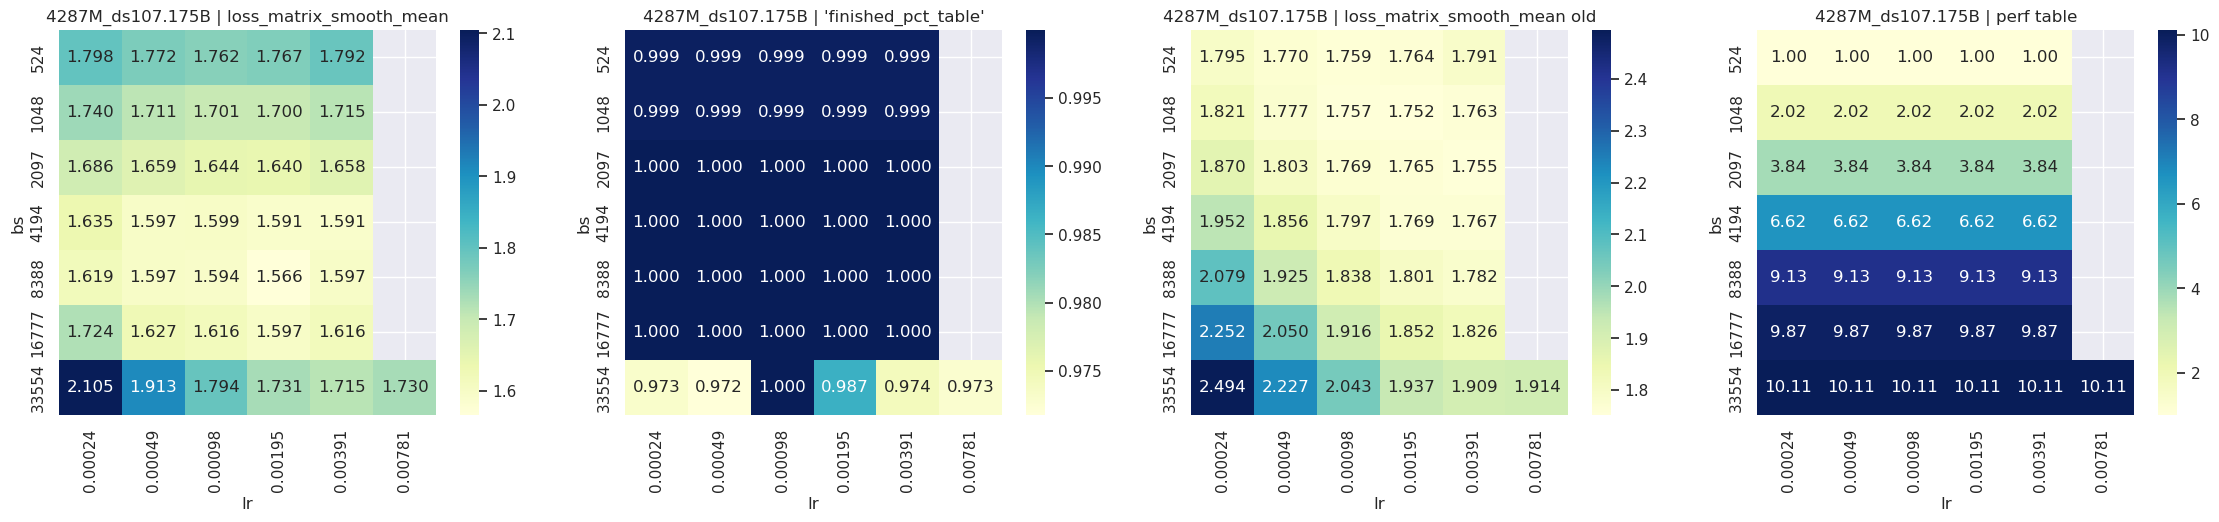

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


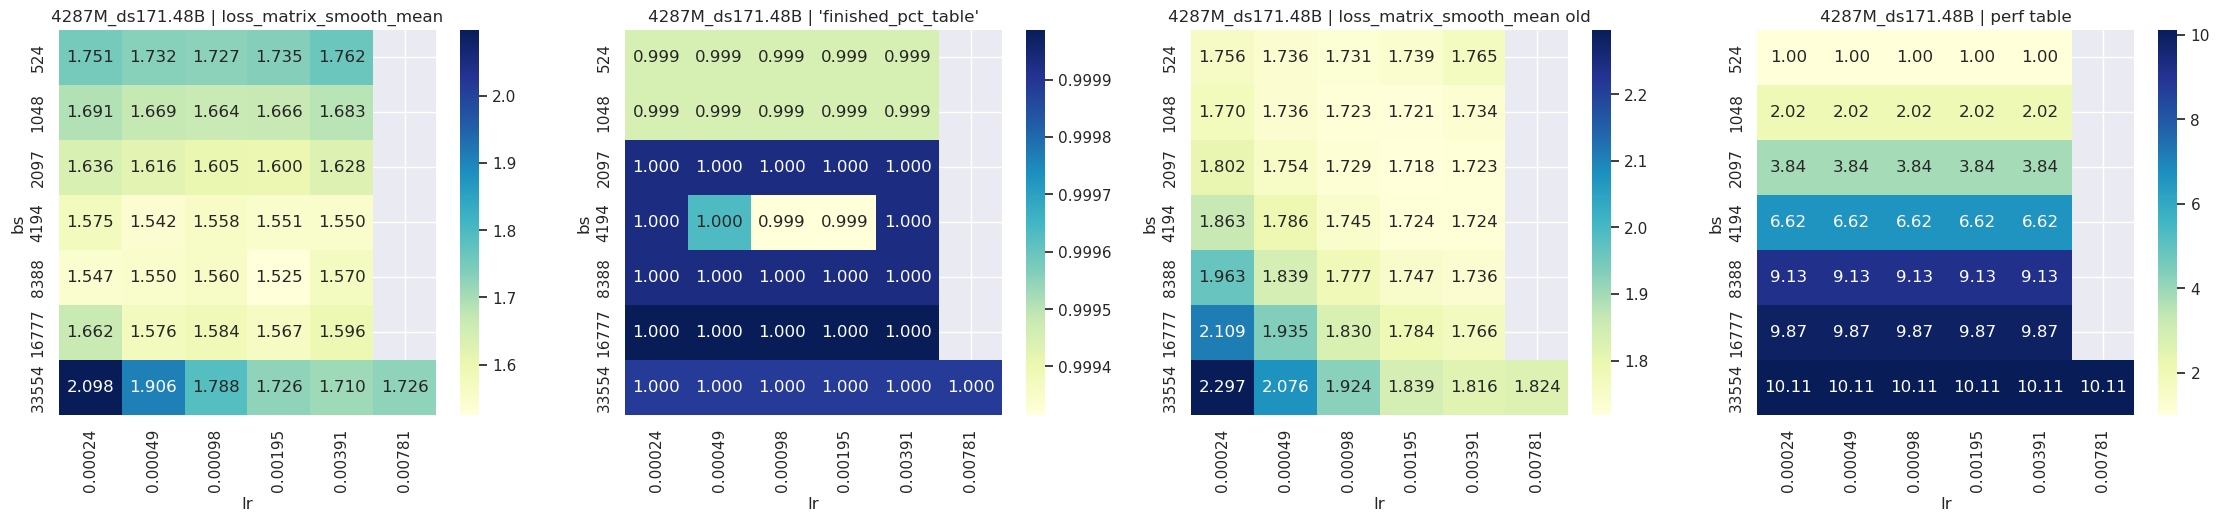

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


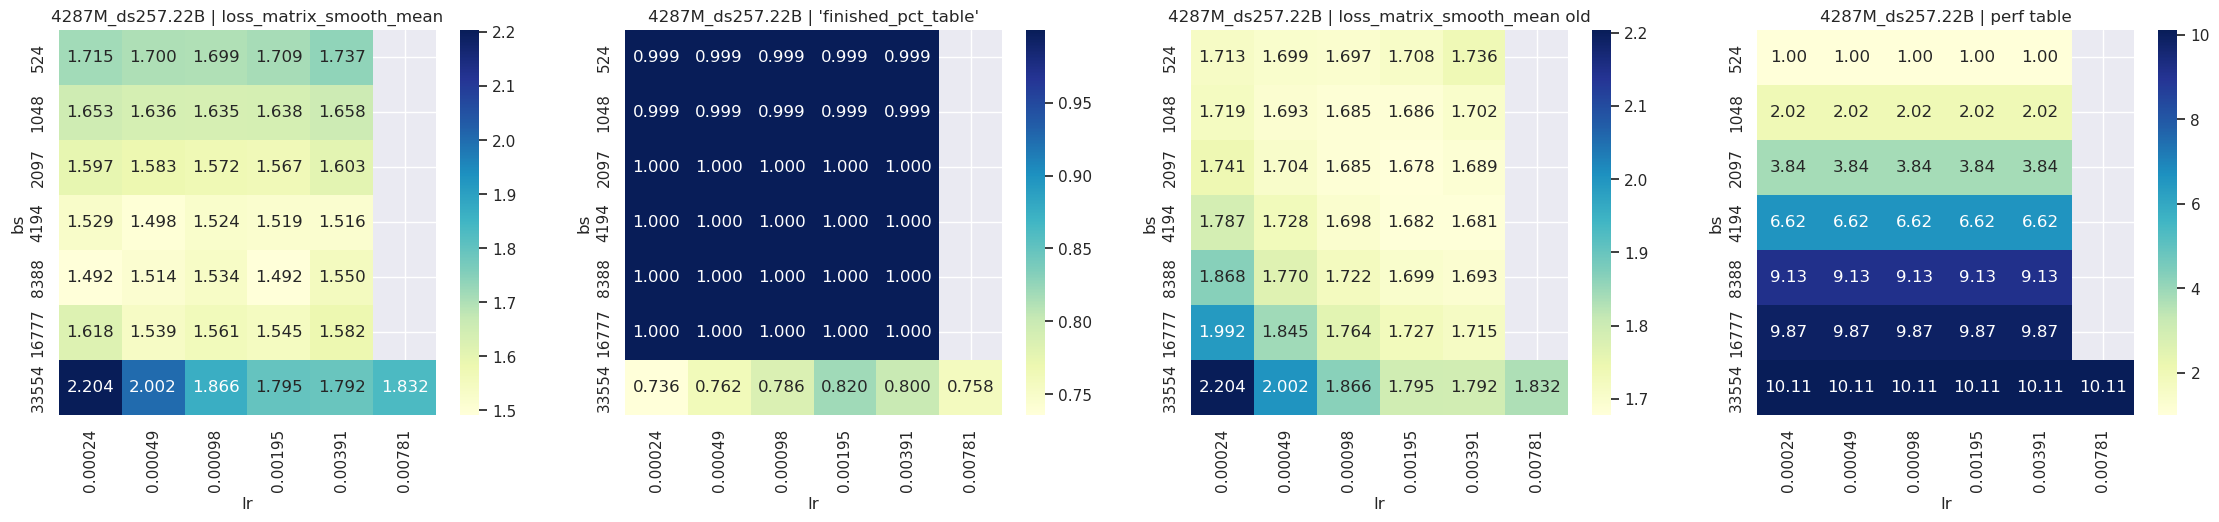

/tmp/ipykernel_1587483/2343747757.py:34: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sns.heatmap((result_old[exp_name]["perf_table"]).applymap(lambda x: round(x, 2)),


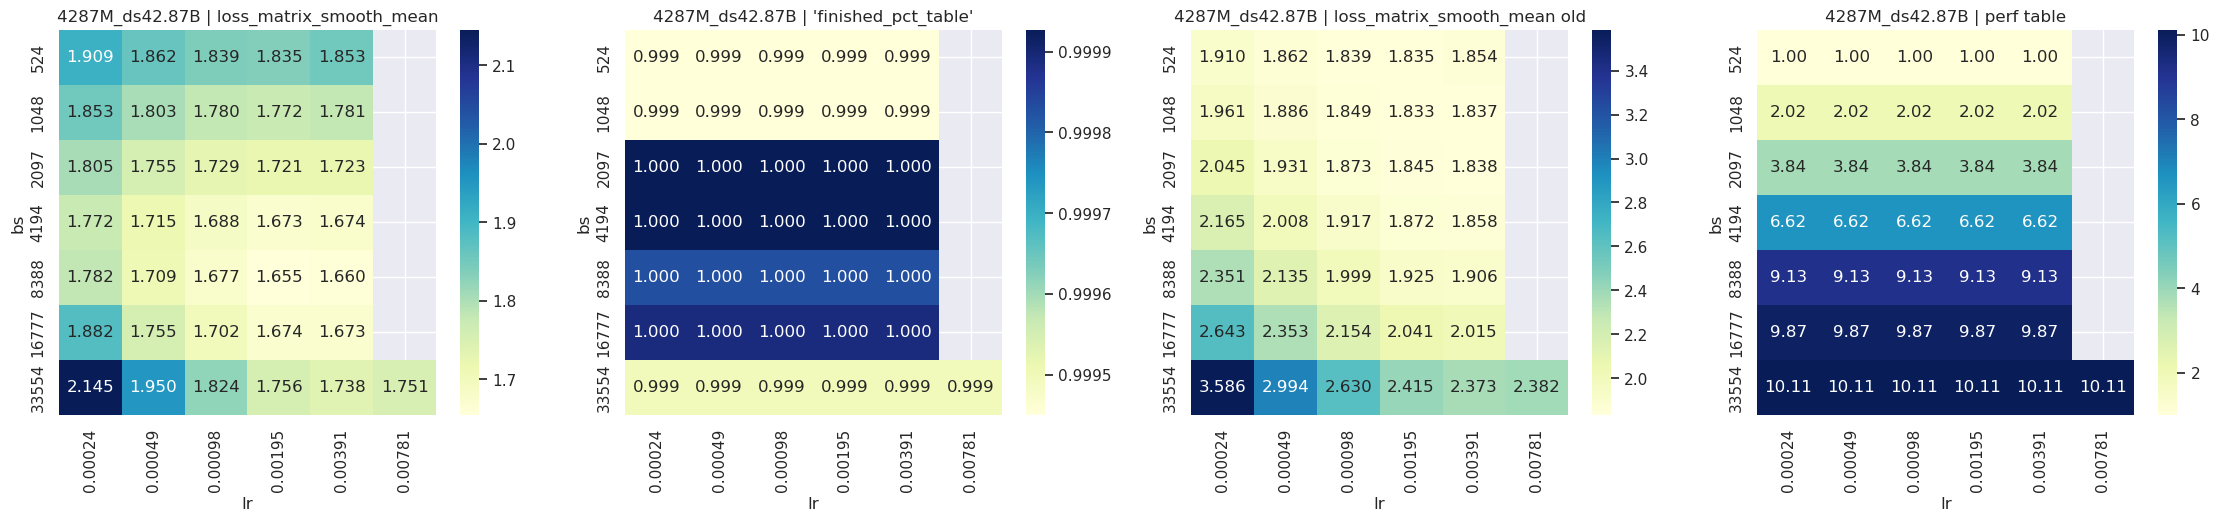

In [38]:
for prefix in results_gathered_copy:
    plot_heat_map(results_gathered_copy, prefix, relative=False, result_old=results_gathered)
    # plot_heat_map(results_gathered_old, prefix, relative=False)
    # size, token = prefix.split("_")
    # mult = token_to_mult[token]
    # bs_res, lr_res = find_opt_hp(prefix)
    # print(bs_res, lr_res)
    # df_opt_bs.loc[size, mult] = bs_res
    # df_opt_lr.loc[size, mult] = lr_res
